# Movie Recommendation System — Preprocessing from Original Rotten Tomatoes Data

This notebook starts from the two original source files:
- `rotten_tomatoes_movies.csv.zip` — movie metadata
- `rotten_tomatoes_movie_reviews.csv.zip` — critic reviews

It creates one record per movie, adds review counts and sentiment summaries, and samples a limited number of review texts per movie for downstream text-based recommendations.

**Why chunk processing?** The reviews archive contains about 1.44 million rows. Processing it in chunks reduces peak memory use compared with loading and merging every review row at once.

## 1. Upload the original ZIP files

In [3]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd
import numpy as np
import re
from collections import defaultdict

MOVIES_ZIP = Path("rotten_tomatoes_movies.csv.zip")
REVIEWS_ZIP = Path("rotten_tomatoes_movie_reviews.csv.zip")

if not MOVIES_ZIP.exists() or not REVIEWS_ZIP.exists():
    try:
        from google.colab import files
        print("Upload BOTH original ZIP files.")
        uploaded = files.upload()
    except ImportError:
        pass

if not MOVIES_ZIP.exists() or not REVIEWS_ZIP.exists():
    raise FileNotFoundError(
        "Please place both ZIP files next to this notebook: "
        "rotten_tomatoes_movies.csv.zip and rotten_tomatoes_movie_reviews.csv.zip"
    )

print("Both source archives are available.")

Upload BOTH original ZIP files.


Saving rotten_tomatoes_movie_reviews.csv.zip to rotten_tomatoes_movie_reviews.csv.zip
Saving rotten_tomatoes_movies.csv.zip to rotten_tomatoes_movies.csv.zip
Both source archives are available.


## 2. Load and inspect movie metadata

In [4]:
with ZipFile(MOVIES_ZIP) as z:
    movie_csvs = [n for n in z.namelist() if n.lower().endswith(".csv")]
    if len(movie_csvs) != 1:
        raise ValueError(f"Expected one CSV in movies archive, found: {movie_csvs}")
    with z.open(movie_csvs[0]) as f:
        movies = pd.read_csv(f, low_memory=False)

print("Movie rows/columns:", movies.shape)
print("Unique movie IDs:", movies["id"].nunique())
display(movies.head())
display(movies.isna().sum().sort_values(ascending=False).head(12).rename("missing_count"))

Movie rows/columns: (143258, 16)
Unique movie IDs: 142052


,id,title,audienceScore,tomatoMeter,rating,ratingContents,releaseDateTheaters,releaseDateStreaming,runtimeMinutes,genre,originalLanguage,director,writer,boxOffice,distributor,soundMix
0,space-zombie-bingo,Space Zombie Bingo!,50.0,NaN,NaN,NaN,NaN,2018-08-25,75.0,"Comedy, Horror, Sci-fi",English,George Ormrod,"George Ormrod,John Sabotta",NaN,NaN,NaN
1,the_green_grass,The Green Grass,NaN,NaN,NaN,NaN,NaN,2020-02-11,114.0,Drama,English,Tiffany Edwards,Tiffany Edwards,NaN,NaN,NaN
2,love_lies,"Love, Lies",43.0,NaN,NaN,NaN,NaN,NaN,120.0,Drama,Korean,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",NaN,NaN,NaN
3,the_sore_losers_1997,Sore Losers,60.0,NaN,NaN,NaN,NaN,2020-10-23,90.0,"Action, Mystery & thriller",English,John Michael McCarthy,John Michael McCarthy,NaN,NaN,NaN
4,dinosaur_island_2002,Dinosaur Island,70.0,NaN,NaN,NaN,NaN,2017-03-27,80.0,"Fantasy, Adventure, Animation",English,Will Meugniot,John Loy,NaN,NaN,NaN


,missing_count
ratingContents,129267
rating,129267
boxOffice,128515
soundMix,127341
distributor,120257
releaseDateTheaters,112485
tomatoMeter,109381
audienceScore,70010
releaseDateStreaming,63838
writer,53142


## 3. Clean the movie table

In [5]:
required = {"id", "title"}
missing = required - set(movies.columns)
if missing:
    raise ValueError(f"Movies table is missing required columns: {sorted(missing)}")

movies = movies.copy()
movies["id"] = movies["id"].astype("string").str.strip()
movies["title"] = movies["title"].astype("string").str.strip()
movies = movies[movies["id"].notna() & movies["id"].ne("")]
movies = movies[movies["title"].notna() & movies["title"].ne("")]
movies = movies.drop_duplicates(subset=["id"], keep="first").reset_index(drop=True)

# Turn the comma-separated genre field into readable text for recommendation features.
if "genre" in movies.columns:
    movies["genre"] = movies["genre"].fillna("").astype(str).str.strip()

for col in ["director", "writer", "originalLanguage", "ratingContents", "genre"]:
    if col in movies.columns:
        movies[col] = movies[col].fillna("").astype(str).str.strip()

print("Clean movie rows:", len(movies))
print("Duplicate IDs:", int(movies["id"].duplicated().sum()))

Clean movie rows: 141687
Duplicate IDs: 0


## 4. Aggregate the reviews in chunks

In [6]:
# Count all reviews and sentiment labels, while retaining at most 5 distinct review texts per movie.
# This keeps the output useful for NLP without concatenating every critic review into a huge field.
CHUNK_SIZE = 100_000
MAX_TEXTS_PER_MOVIE = 5

review_counts = defaultdict(int)
positive_counts = defaultdict(int)
negative_counts = defaultdict(int)
fresh_counts = defaultdict(int)
rotten_counts = defaultdict(int)
review_texts = defaultdict(list)

with ZipFile(REVIEWS_ZIP) as z:
    review_csvs = [n for n in z.namelist() if n.lower().endswith(".csv")]
    if len(review_csvs) != 1:
        raise ValueError(f"Expected one CSV in reviews archive, found: {review_csvs}")
    with z.open(review_csvs[0]) as f:
        reader = pd.read_csv(
            f,
            usecols=["id", "reviewText", "scoreSentiment", "reviewState"],
            chunksize=CHUNK_SIZE,
            low_memory=False,
        )
        for chunk_number, chunk in enumerate(reader, start=1):
            chunk["id"] = chunk["id"].astype("string").str.strip()
            chunk = chunk[chunk["id"].notna() & chunk["id"].ne("")]
            grouped = chunk.groupby("id", sort=False)

            for movie_id, group in grouped:
                review_counts[movie_id] += len(group)
                sentiments = group["scoreSentiment"].astype("string").str.upper()
                states = group["reviewState"].astype("string").str.lower()
                positive_counts[movie_id] += int(sentiments.eq("POSITIVE").sum())
                negative_counts[movie_id] += int(sentiments.eq("NEGATIVE").sum())
                fresh_counts[movie_id] += int(states.eq("fresh").sum())
                rotten_counts[movie_id] += int(states.eq("rotten").sum())

                existing = review_texts[movie_id]
                if len(existing) < MAX_TEXTS_PER_MOVIE:
                    for value in group["reviewText"].dropna().astype(str):
                        value = re.sub(r"\s+", " ", value).strip()
                        if value and value not in existing:
                            existing.append(value[:1500])
                        if len(existing) >= MAX_TEXTS_PER_MOVIE:
                            break

            if chunk_number % 3 == 0:
                print(f"Processed {chunk_number * CHUNK_SIZE:,} review rows...")

print("Review aggregation complete.")
print("Movie IDs with reviews:", len(review_counts))

Processed 300,000 review rows...
Processed 600,000 review rows...
Processed 900,000 review rows...
Processed 1,200,000 review rows...
Processed 1,500,000 review rows...
Review aggregation complete.
Movie IDs with reviews: 69263


## 5. Build the review summary table

In [7]:
review_summary = pd.DataFrame({
    "id": list(review_counts.keys()),
    "reviewCount": [review_counts[k] for k in review_counts],
    "positiveReviewCount": [positive_counts[k] for k in review_counts],
    "negativeReviewCount": [negative_counts[k] for k in review_counts],
    "freshReviewCount": [fresh_counts[k] for k in review_counts],
    "rottenReviewCount": [rotten_counts[k] for k in review_counts],
    "sampledReviewText": [" ".join(review_texts[k]) for k in review_counts],
})

review_summary["positiveReviewShare"] = (
    review_summary["positiveReviewCount"] / review_summary["reviewCount"]
)
review_summary["freshReviewShare"] = (
    review_summary["freshReviewCount"] / review_summary["reviewCount"]
)

display(review_summary.head())
print("Review summary rows:", len(review_summary))

,id,reviewCount,positiveReviewCount,negativeReviewCount,freshReviewCount,rottenReviewCount,sampledReviewText,positiveReviewShare,freshReviewShare
0,beavers,1,1,0,1,0,Timed to be just long enough for most youngste...,1.000000,1.000000
1,blood_mask,1,0,1,0,1,It doesn't matter if a movie costs 300 million...,0.000000,0.000000
2,city_hunter_shinjuku_private_eyes,2,1,1,1,1,The choreography is so precise and lifelike at...,0.500000,0.500000
3,dangerous_men_2015,10,5,5,5,5,Its clumsy determination is endearing and some...,0.500000,0.500000
4,small_town_wisconsin,12,10,2,10,2,Small Town Wisconsin could hit some home truth...,0.833333,0.833333


Review summary rows: 69263


## 6. Merge movie metadata with review summaries

In [8]:
movies_with_reviews = movies.merge(
    review_summary,
    on="id",
    how="left",
    validate="one_to_one",
)

count_cols = [
    "reviewCount", "positiveReviewCount", "negativeReviewCount",
    "freshReviewCount", "rottenReviewCount"
]
for col in count_cols:
    if col in movies_with_reviews.columns:
        movies_with_reviews[col] = movies_with_reviews[col].fillna(0).astype("int64")

for col in ["positiveReviewShare", "freshReviewShare"]:
    if col in movies_with_reviews.columns:
        movies_with_reviews[col] = movies_with_reviews[col].fillna(0.0)

movies_with_reviews["sampledReviewText"] = movies_with_reviews["sampledReviewText"].fillna("")

print("Merged shape:", movies_with_reviews.shape)
print("Unique IDs:", movies_with_reviews["id"].nunique())
print("Duplicate IDs:", int(movies_with_reviews["id"].duplicated().sum()))
print("Movies with no matching reviews:", int(movies_with_reviews["reviewCount"].eq(0).sum()))
display(movies_with_reviews[["id", "title", "genre", "reviewCount", "positiveReviewShare", "sampledReviewText"]].head())

Merged shape: (141687, 24)
Unique IDs: 141687
Duplicate IDs: 0
Movies with no matching reviews: 72610


,id,title,genre,reviewCount,positiveReviewShare,sampledReviewText
0,space-zombie-bingo,Space Zombie Bingo!,"Comedy, Horror, Sci-fi",0,0.0,
1,the_green_grass,The Green Grass,Drama,0,0.0,
2,love_lies,"Love, Lies",Drama,2,1.0,Though let down by its routine love triangle n...
3,the_sore_losers_1997,Sore Losers,"Action, Mystery & thriller",0,0.0,
4,dinosaur_island_2002,Dinosaur Island,"Fantasy, Adventure, Animation",0,0.0,


## 7. Final validation

In [9]:
assert movies_with_reviews["id"].is_unique
assert movies_with_reviews["title"].notna().all()
assert movies_with_reviews["reviewCount"].ge(0).all()
assert movies_with_reviews["positiveReviewShare"].between(0, 1).all()
assert movies_with_reviews["freshReviewShare"].between(0, 1).all()

print("Validation passed.")
print(f"Movie records: {len(movies_with_reviews):,}")
print(f"Unique movie IDs: {movies_with_reviews['id'].nunique():,}")
print(f"Duplicate movie IDs: {movies_with_reviews['id'].duplicated().sum()}")

Validation passed.
Movie records: 141,687
Unique movie IDs: 141,687
Duplicate movie IDs: 0


## 8. Save the processed dataset

In [10]:
OUTPUT_PATH = Path("movies_with_reviews.csv")
movies_with_reviews.to_csv(OUTPUT_PATH, index=False)
print(f"Saved {OUTPUT_PATH.resolve()} ({OUTPUT_PATH.stat().st_size / (1024**2):.1f} MB)")

Saved /content/movies_with_reviews.csv (48.0 MB)


## Notes for the recommendation model

- Use `title`, `genre`, `director`, `writer`, `originalLanguage`, `ratingContents`, and `sampledReviewText` to build content features, choosing only the columns that are useful and sufficiently populated.
- Do not treat `positiveReviewShare` as recommendation accuracy. It summarizes review sentiment only.
- This notebook caps review text at five distinct reviews per movie to limit file size and memory use. Review counts and sentiment counts still use all review rows.
- Check the original dataset's license and attribution requirements before publishing the processed dataset.

In [11]:
DATA_PATH = Path("/content/movies_with_reviews.csv")

if not DATA_PATH.exists():
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = Path(next(iter(uploaded)))

movies = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset shape:", movies.shape)
print("Unique movie IDs:", movies["id"].nunique())
print("Duplicate movie IDs:", movies["id"].duplicated().sum())

display(movies.head())
display(movies.info())
display(movies.describe(include="all").T)


Dataset shape: (141687, 24)
Unique movie IDs: 141687
Duplicate movie IDs: 0


,id,title,audienceScore,tomatoMeter,rating,ratingContents,releaseDateTheaters,releaseDateStreaming,runtimeMinutes,genre,...,distributor,soundMix,reviewCount,positiveReviewCount,negativeReviewCount,freshReviewCount,rottenReviewCount,sampledReviewText,positiveReviewShare,freshReviewShare
0,space-zombie-bingo,Space Zombie Bingo!,50.0,NaN,NaN,NaN,NaN,2018-08-25,75.0,"Comedy, Horror, Sci-fi",...,NaN,NaN,0,0,0,0,0,NaN,0.0,0.0
1,the_green_grass,The Green Grass,NaN,NaN,NaN,NaN,NaN,2020-02-11,114.0,Drama,...,NaN,NaN,0,0,0,0,0,NaN,0.0,0.0
2,love_lies,"Love, Lies",43.0,NaN,NaN,NaN,NaN,NaN,120.0,Drama,...,NaN,NaN,2,2,0,2,0,Though let down by its routine love triangle n...,1.0,1.0
3,the_sore_losers_1997,Sore Losers,60.0,NaN,NaN,NaN,NaN,2020-10-23,90.0,"Action, Mystery & thriller",...,NaN,NaN,0,0,0,0,0,NaN,0.0,0.0
4,dinosaur_island_2002,Dinosaur Island,70.0,NaN,NaN,NaN,NaN,2017-03-27,80.0,"Fantasy, Adventure, Animation",...,NaN,NaN,0,0,0,0,0,NaN,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 141687 entries, 0 to 141686
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    141687 non-null  object 
 1   title                 141687 non-null  object 
 2   audienceScore         72628 non-null   float64
 3   tomatoMeter           33574 non-null   float64
 4   rating                13855 non-null   object 
 5   ratingContents        13855 non-null   object 
 6   releaseDateTheaters   30501 non-null   object 
 7   releaseDateStreaming  78690 non-null   object 
 8   runtimeMinutes        128275 non-null  float64
 9   genre                 130986 non-null  object 
 10  originalLanguage      128237 non-null  object 
 11  director              137795 non-null  object 
 12  writer                89325 non-null   object 
 13  boxOffice             14614 non-null   object 
 14  distributor           22792 non-null   object 
 15  

None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,141687,141687,awakening-2005,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,141687,126403,The Return,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
audienceScore,72628.0,NaN,NaN,NaN,55.669356,24.55069,0.0,37.0,57.0,76.0,100.0
tomatoMeter,33574.0,NaN,NaN,NaN,65.764818,28.020382,0.0,45.0,73.0,89.0,100.0
rating,13855,10,R,7665,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ratingContents,13855,8352,['Language'],355,NaN,NaN,NaN,NaN,NaN,NaN,NaN
releaseDateTheaters,30501,12055,2018-09-14,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
releaseDateStreaming,78690,4725,2017-05-22,1225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runtimeMinutes,128275.0,NaN,NaN,NaN,93.703902,28.09071,1.0,84.0,92.0,103.0,2700.0
genre,130986,2911,Drama,27605,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing_Count,Missing_Percentage
ratingContents,127832,90.22
rating,127832,90.22
boxOffice,127073,89.69
soundMix,125904,88.86
distributor,118895,83.91
releaseDateTheaters,111186,78.47
tomatoMeter,108113,76.30
sampledReviewText,74262,52.41
audienceScore,69059,48.74
releaseDateStreaming,62997,44.46


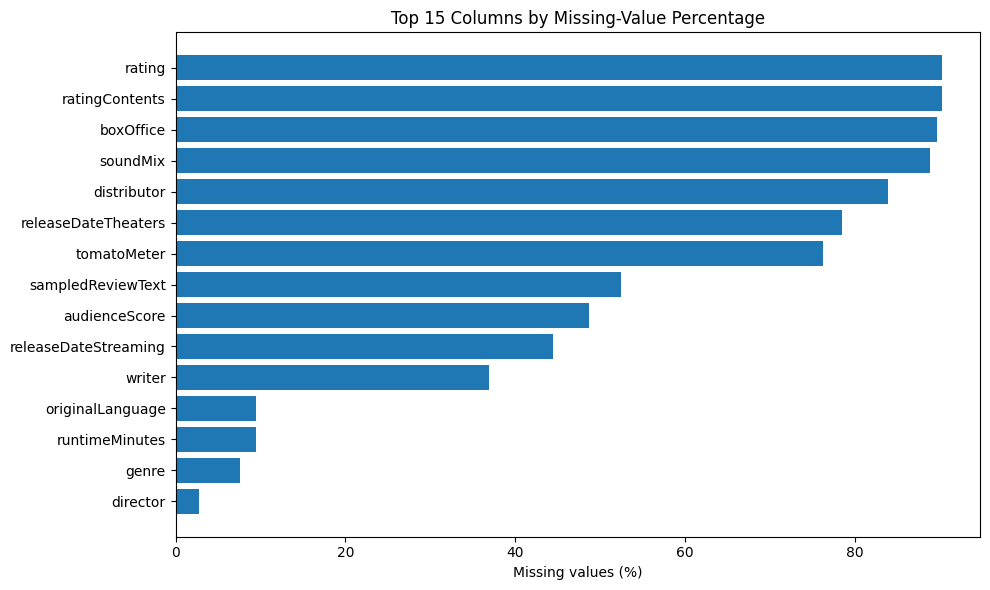

In [12]:

import matplotlib.pyplot as plt
import seaborn as sns

# Missing values by column
missing = pd.DataFrame({
    "Missing_Count": movies.isna().sum(),
    "Missing_Percentage": movies.isna().mean().mul(100).round(2)
}).sort_values("Missing_Percentage", ascending=False)

display(missing)

# Visualize the 15 columns with the highest missing percentages
top_missing = missing.head(15).sort_values("Missing_Percentage")

plt.figure(figsize=(10, 6))
plt.barh(top_missing.index, top_missing["Missing_Percentage"])
plt.xlabel("Missing values (%)")
plt.title("Top 15 Columns by Missing-Value Percentage")
plt.tight_layout()
plt.show()


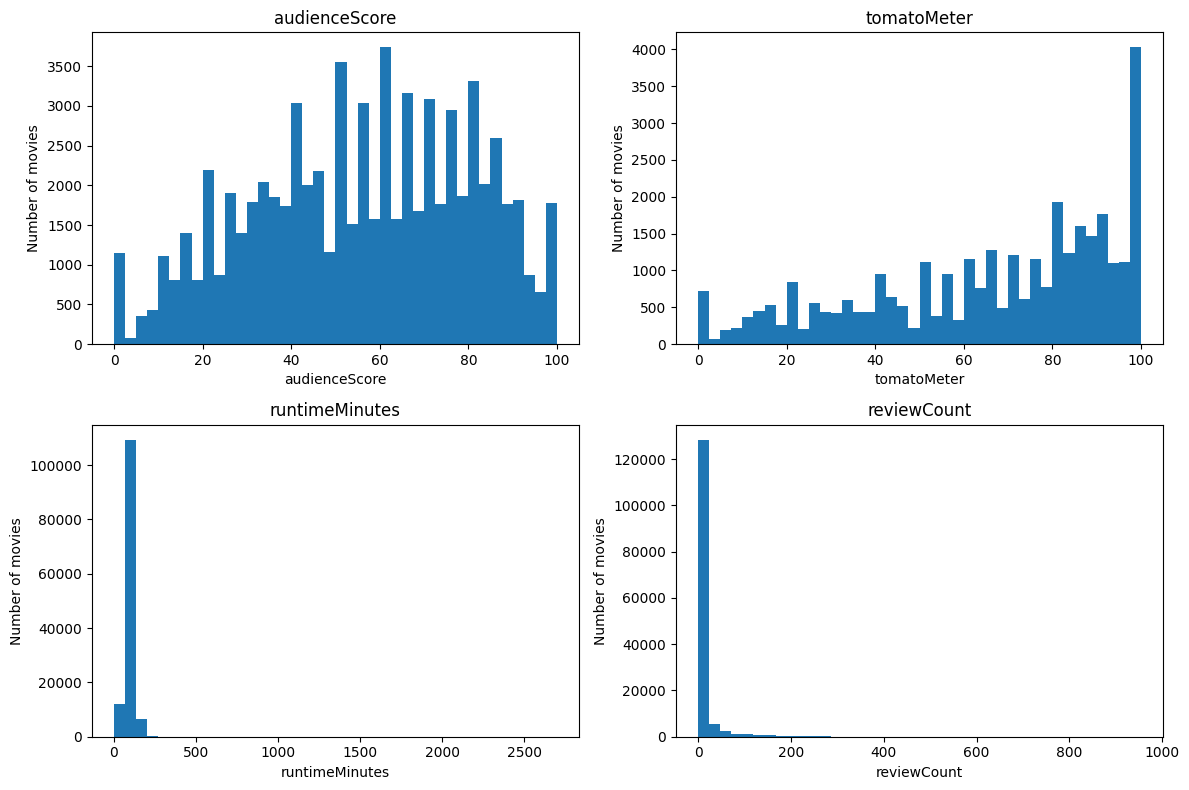

In [13]:

import matplotlib.pyplot as plt

columns = [
    "audienceScore",
    "tomatoMeter",
    "runtimeMinutes",
    "reviewCount"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), columns):
    data = movies[col].dropna()
    ax.hist(data, bins=40)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of movies")

plt.tight_layout()
plt.show()


In [14]:

numeric_cols = [
    "audienceScore",
    "tomatoMeter",
    "runtimeMinutes",
    "reviewCount"
]

outlier_results = []

for col in numeric_cols:
    values = movies[col].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Median": values.median(),
        "Q3": q3,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": round(
            len(outliers) / len(values) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(2))


,Feature,Q1,Median,Q3,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,audienceScore,37.0,57.0,76.0,-21.5,134.5,0,0.00
1,tomatoMeter,45.0,73.0,89.0,-21.0,155.0,0,0.00
2,runtimeMinutes,84.0,92.0,103.0,55.5,131.5,14578,11.36
3,reviewCount,0.0,0.0,4.0,-6.0,10.0,21857,15.43


In [15]:

runtime_check = movies[
    ["id", "title", "runtimeMinutes"]
].dropna(subset=["runtimeMinutes"]).copy()

runtime_check = runtime_check.sort_values("runtimeMinutes")

print("10 shortest runtimes:")
display(runtime_check.head(10))

print("20 longest runtimes:")
display(
    runtime_check.tail(20).sort_values(
        "runtimeMinutes", ascending=False
    )
)


10 shortest runtimes:


,id,title,runtimeMinutes
114190,la_fee_aux_choux,La fée aux choux,1.0
84531,da_zhangyu,Dà zhangyú,1.0
43116,tenali_raman,Tenali Raman,1.0
116138,harry_and_meghan_a_very_modern_romance_2018,Harry & Meghan: A Royal Romance: Trailer,1.0
98303,under_the_stars_and_stripes,Stars and Stripes,1.0
17569,two_minutes_to_zero,Two Minutes to Zero,1.0
119907,kalam_vellum,Kalam Vellum,1.0
24732,ripples,Ripples,1.0
11446,chitra_pournami,Chitra Pournami,1.0
90445,a_photographic_contortion,The Big Swallow,1.0


20 longest runtimes:


,id,title,runtimeMinutes
69774,we_hear_you,We Hear You,2700.0
134916,red_wine_and_rain,Red Wine and Rain,1013.0
82242,heimat,Heimat,940.0
128918,yu_gong_yi_shan,How Yukong Moved the Mountains,763.0
102523,nights_and_days,Nights and Days,632.0
123182,evolution_of_a_filipino_family,Evolution of a Filipino Family,593.0
100078,the_decalogue,The Decalogue,584.0
103863,shoah,Shoah,561.0
122751,death-in-the-land-of-encantos,Death in the Land of Encantos,540.0
118282,wrestlemania_xxx,WWE: The True Story of WrestleMania,540.0


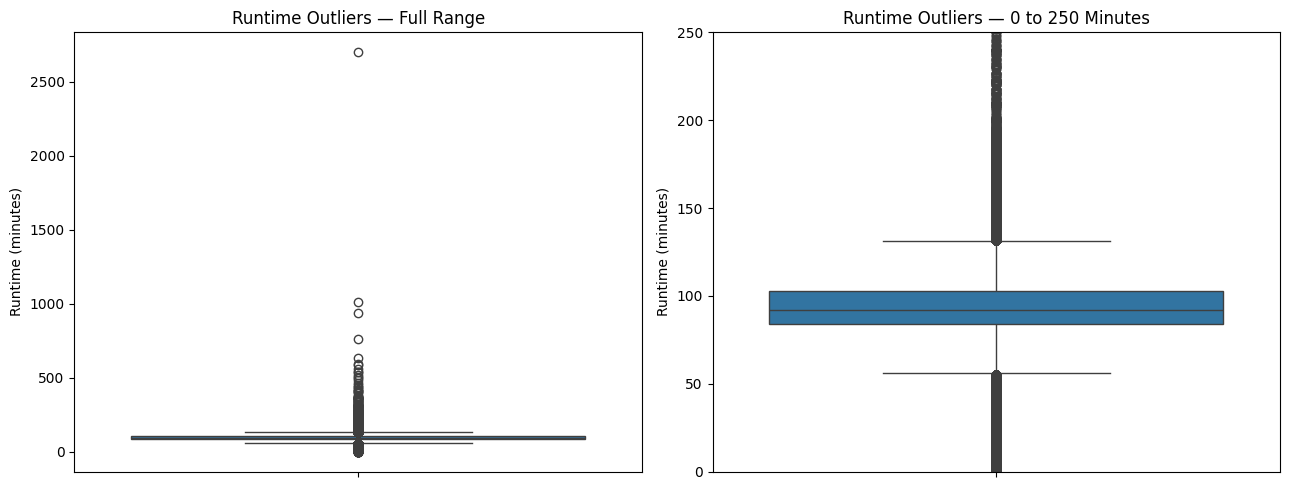

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Full runtime range
sns.boxplot(y=movies["runtimeMinutes"].dropna(), ax=axes[0])
axes[0].set_title("Runtime Outliers — Full Range")
axes[0].set_ylabel("Runtime (minutes)")

# Zoomed view of typical runtimes
sns.boxplot(y=movies["runtimeMinutes"].dropna(), ax=axes[1])
axes[1].set_ylim(0, 250)
axes[1].set_title("Runtime Outliers — 0 to 250 Minutes")
axes[1].set_ylabel("Runtime (minutes)")

plt.tight_layout()
plt.show()


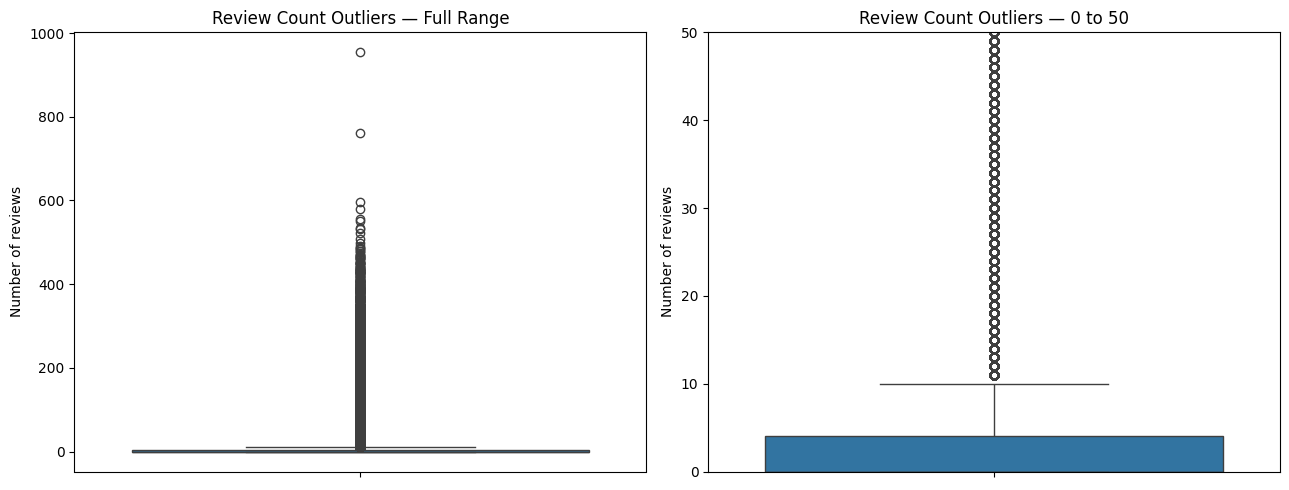

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Full distribution
sns.boxplot(y=movies["reviewCount"], ax=axes[0])
axes[0].set_title("Review Count Outliers — Full Range")
axes[0].set_ylabel("Number of reviews")

# Zoomed distribution
sns.boxplot(y=movies["reviewCount"], ax=axes[1])
axes[1].set_ylim(0, 50)
axes[1].set_title("Review Count Outliers — 0 to 50")
axes[1].set_ylabel("Number of reviews")

plt.tight_layout()
plt.show()


In [ ]:

review_check = movies[
    ["id", "title", "reviewCount"]
].sort_values("reviewCount", ascending=False)

display(review_check.head(20))


,id,title,reviewCount
49348,parasite_2019,Parasite,954
128528,ant_man_and_the_wasp_quantumania,Ant-Man and The Wasp: Quantumania,760
57718,joker_2019,Joker,597
118311,once_upon_a_time_in_hollywood,Once Upon a Time... In Hollywood,580
106411,avengers_endgame,Avengers: Endgame,555
30502,captain_marvel,Captain Marvel,552
121726,a_star_is_born_2018,A Star Is Born,534
40434,black_panther_2018,Black Panther,531
5630,star_wars_the_rise_of_skywalker,Star Wars: The Rise of Skywalker,522
90291,the_batman,The Batman,508



## Outlier Analysis — Findings

The IQR method identified potential outliers in runtimeMinutes
and reviewCount.

- Runtime: 14,578 potential outliers (11.36%).
- Review count: 21,857 potential outliers (15.43%).
- Audience and Tomatometer scores had no IQR outliers.
- Review counts are strongly right-skewed, with a small number
  of movies receiving substantially more reviews.
- High review counts are not necessarily data errors.
- Extreme runtimes require further validation against source
  metadata before any records are modified.

No records were automatically removed solely because they
were flagged as statistical outliers.


,Genre,Movie_Count
0,Drama,55084
1,Comedy,29827
2,Documentary,18736
3,Mystery & thriller,18024
4,Action,11090
5,Horror,10939
6,Romance,10751
7,Adventure,7714
8,Crime,6303
9,Fantasy,4548


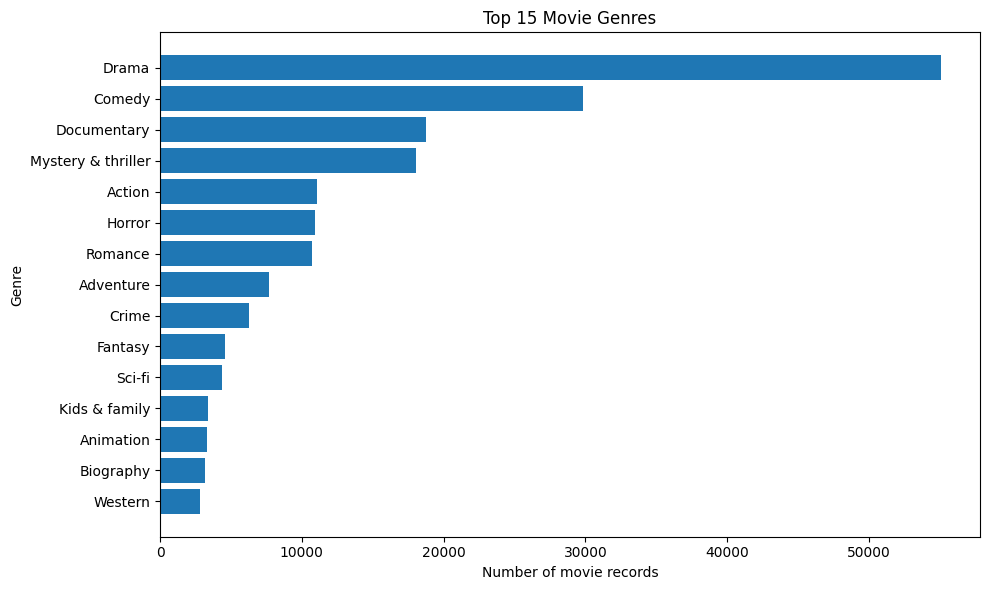

In [ ]:

from collections import Counter
import matplotlib.pyplot as plt

genre_counts = Counter()

for genres in movies["genre"].dropna():
    for genre in str(genres).split(","):
        genre = genre.strip()
        if genre:
            genre_counts[genre] += 1

top_genres = genre_counts.most_common(15)

genre_df = pd.DataFrame(
    top_genres,
    columns=["Genre", "Movie_Count"]
)

display(genre_df)

plt.figure(figsize=(10, 6))
plt.barh(
    genre_df["Genre"][::-1],
    genre_df["Movie_Count"][::-1]
)
plt.title("Top 15 Movie Genres")
plt.xlabel("Number of movie records")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


### Genre Distribution — Key Findings

- Drama is the most frequently recorded genre in the dataset.
- Comedy is the second most frequent genre, followed by Documentary and Mystery & thriller.
- Action, Horror and Romance have similar representation.
- The genre distribution is imbalanced, with Drama substantially more frequent than most other categories.
- Movies can belong to multiple genres, so the counts are not mutually exclusive.

**Implication for the recommendation system:** Genre can be a useful content feature, but recommendations should combine it with other available information, such as movie titles, directors and review text, to avoid over-relying on the dominant genre.

Movies with both scores: 30052


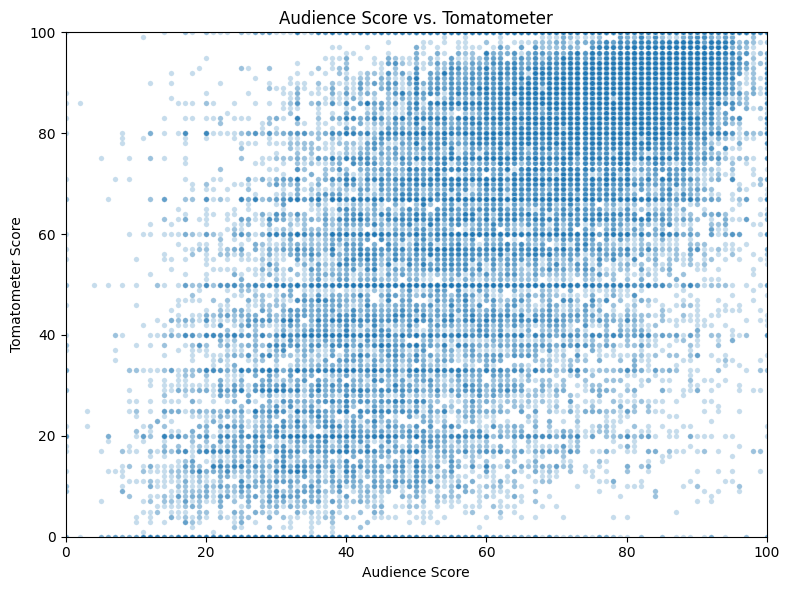

Pearson correlation: 0.602


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

score_data = movies[
    ["audienceScore", "tomatoMeter"]
].dropna()

print("Movies with both scores:", len(score_data))

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=score_data,
    x="audienceScore",
    y="tomatoMeter",
    alpha=0.25,
    s=15
)

plt.title("Audience Score vs. Tomatometer")
plt.xlabel("Audience Score")
plt.ylabel("Tomatometer Score")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print(
    "Pearson correlation:",
    round(
        score_data["audienceScore"].corr(
            score_data["tomatoMeter"]
        ),
        3
    )
)


In [ ]:
print(
    "Pearson correlation:",
    round(
        score_data["audienceScore"].corr(
            score_data["tomatoMeter"]
        ),
        3
    )
)

Pearson correlation: 0.602


### Audience Score vs. Tomatometer — EDA Insight

The Pearson correlation coefficient between audience scores and Tomatometer scores is **0.602**, indicating a moderate positive linear relationship among movies with both scores available.

- Movies with higher critic scores tend, on average, to have higher audience scores.
- The scatter plot shows considerable variation, suggesting that critic and audience opinions do not always agree.
- Correlation does not imply causation.
- The analysis excludes movies missing either score, so the result may not represent the entire dataset.

**Recommendation-system implication:** Ratings can be useful for analyzing movie preferences and validating results, but content-based recommendations should primarily use movie features such as genres, directors and review text.


Review sentiment totals:


,Count
Positive reviews,960209
Negative reviews,479277


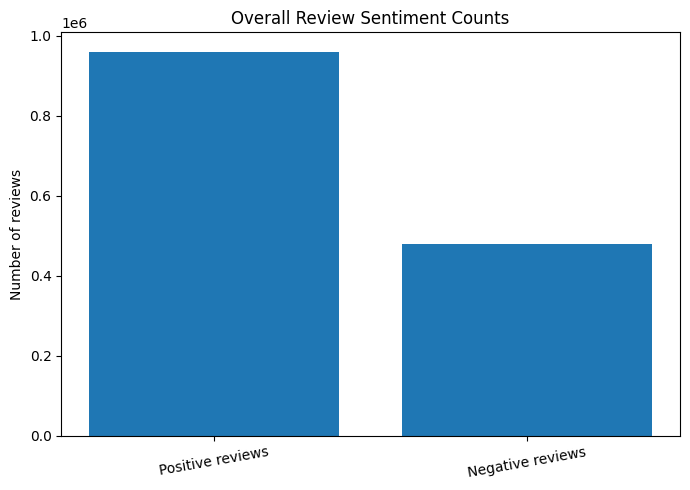

In [ ]:

import matplotlib.pyplot as plt

sentiment_totals = pd.Series({
    "Positive reviews": movies["positiveReviewCount"].sum(),
    "Negative reviews": movies["negativeReviewCount"].sum()
})

print("Review sentiment totals:")
display(sentiment_totals.to_frame("Count"))

plt.figure(figsize=(7, 5))
plt.bar(
    sentiment_totals.index,
    sentiment_totals.values
)
plt.title("Overall Review Sentiment Counts")
plt.ylabel("Number of reviews")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


### Review Sentiment Analysis — Key Findings

- The dataset contains substantially more positive reviews than negative reviews.
- The aggregate sentiment distribution is imbalanced toward positive reviews.
- Review counts vary considerably across movies, so aggregate totals do not describe the sentiment of a typical movie.
- Movies with no recorded reviews should be distinguished from movies with neutral sentiment.
- Positive and negative review counts describe sentiment distribution; they do not measure recommendation-system accuracy.

**Recommendation-system implication:** Review sentiment can help describe audience or critic reception, but it should be combined with movie content features rather than used alone to recommend similar movies.



Movies with at least one review: 69077
Median positive review share: 0.75


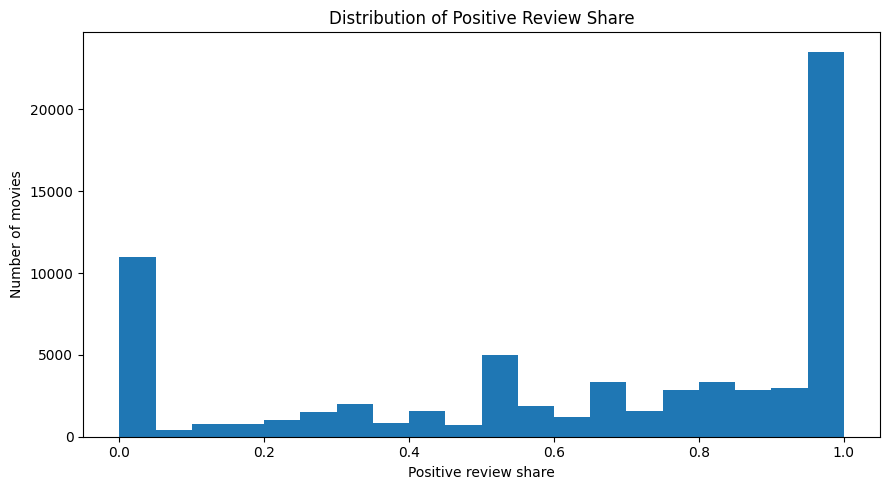

In [ ]:

# Include only movies that have at least one review
reviewed_movies = movies[movies["reviewCount"] > 0].copy()

print("Movies with at least one review:", len(reviewed_movies))

print(
    "Median positive review share:",
    round(reviewed_movies["positiveReviewShare"].median(), 3)
)

plt.figure(figsize=(9, 5))
plt.hist(
    reviewed_movies["positiveReviewShare"].dropna(),
    bins=20
)
plt.title("Distribution of Positive Review Share")
plt.xlabel("Positive review share")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()


### Positive Review Share — Key Findings

- The distribution has substantial peaks near 0 and 1.
- Some movies have entirely positive or entirely non-positive recorded review sentiment.
- Movies with small review counts can have extreme sentiment shares based on only a few observations.
- Sentiment share should be interpreted alongside review count.
- Movies with no reviews must be excluded from sentiment-share comparisons.

**Recommendation-system implication:** Sentiment can provide supplementary information about movie reception, but it should not be treated as recommendation accuracy or used without considering review volume.

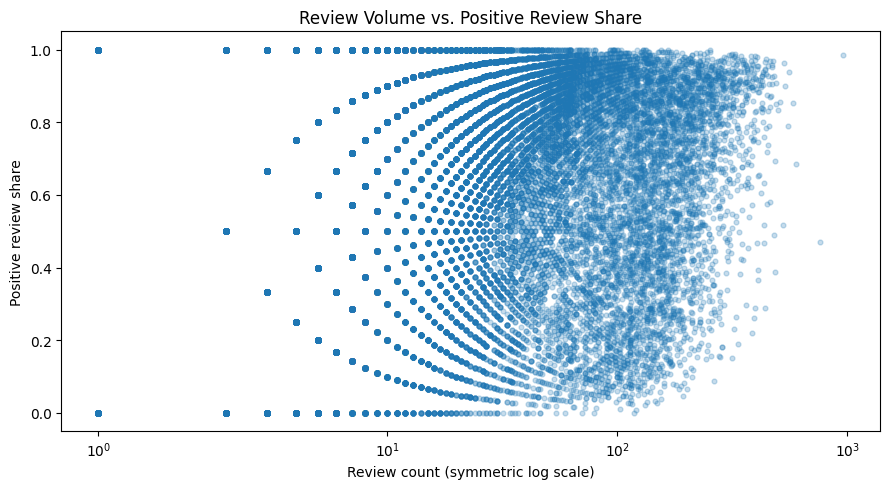

In [ ]:

reviewed_movies = movies[movies["reviewCount"] > 0].copy()

plt.figure(figsize=(9, 5))

plt.scatter(
    reviewed_movies["reviewCount"],
    reviewed_movies["positiveReviewShare"],
    alpha=0.25,
    s=12
)

plt.xscale("symlog")
plt.title("Review Volume vs. Positive Review Share")
plt.xlabel("Review count (symmetric log scale)")
plt.ylabel("Positive review share")
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()


### Review Volume vs. Positive Review Share — Findings

- Movies with very few reviews frequently have sentiment shares of exactly 0 or 1.
- Sentiment shares take discrete values because they are calculated from integer review counts.
- Movies with more reviews show a broader range of observed sentiment shares.
- Extreme sentiment shares based on few reviews should be interpreted cautiously.
- Review volume should be considered when using sentiment as a supporting feature.

**Recommendation-system implication:** Review sentiment may help describe movie reception, but content features should remain central to the content-based recommendation model.

Movies with theatrical release dates: 30501


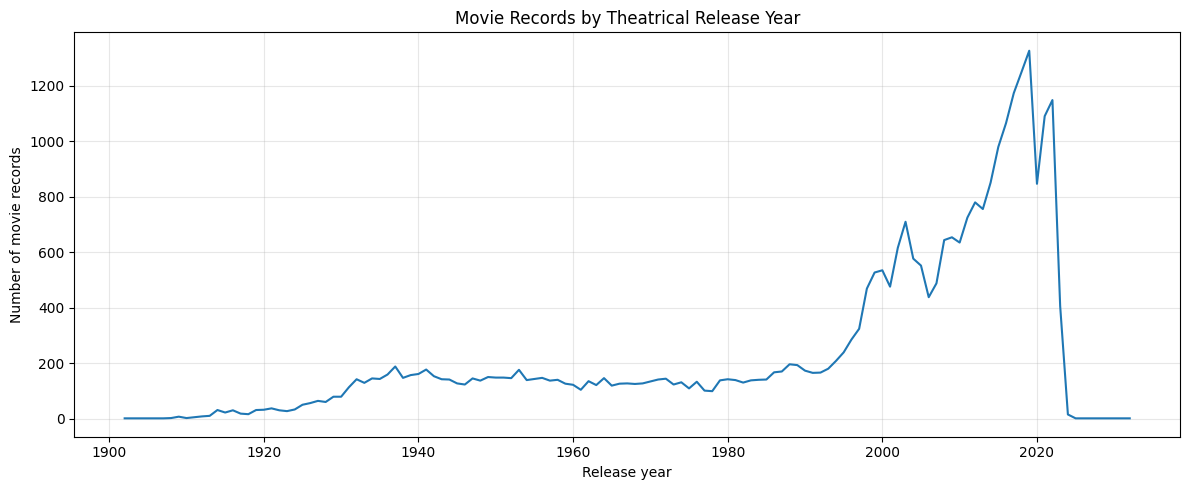

In [ ]:

# Convert release dates to datetime and extract release year
movies["releaseDateTheaters"] = pd.to_datetime(
    movies["releaseDateTheaters"],
    errors="coerce"
)

movies["releaseYear"] = movies["releaseDateTheaters"].dt.year

year_counts = (
    movies["releaseYear"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

print("Movies with theatrical release dates:", year_counts.sum())

plt.figure(figsize=(12, 5))
plt.plot(year_counts.index, year_counts.values)
plt.title("Movie Records by Theatrical Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of movie records")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Theatrical Release-Year Analysis — Findings

- Movie records with theatrical release dates increase substantially from the late 1990s through the 2010s.
- The highest point in the plotted series occurs around 2019.
- The sharp decline after 2020 may reflect incomplete data coverage or missing release dates.
- This chart represents records with available theatrical release dates, not necessarily the actual number of films produced or released each year.

**Limitation:** Recent-year trends should not be interpreted as industry-wide production trends without validating dataset completeness.

In [ ]:

year_summary = (
    movies.loc[movies["releaseYear"].notna()]
    .groupby("releaseYear")
    .size()
    .rename("Movie_Records")
    .reset_index()
)

year_summary["releaseYear"] = year_summary["releaseYear"].astype(int)

display(
    year_summary[year_summary["releaseYear"] >= 2018]
    .sort_values("releaseYear")
)


,releaseYear,Movie_Records
114,2018,1250
115,2019,1327
116,2020,847
117,2021,1091
118,2022,1149
119,2023,406
120,2024,15
121,2025,1
122,2026,1
123,2028,1


In [ ]:

# Inspect records with theatrical release dates after 2026
future_movies = movies.loc[
    movies["releaseDateTheaters"].dt.year > 2026,
    ["id", "title", "releaseDateTheaters"]
].sort_values("releaseDateTheaters")

print("Records with theatrical release dates after 2026:")
display(future_movies)

# Inspect the most recent years in detail
recent_movies = movies.loc[
    movies["releaseDateTheaters"].dt.year >= 2023,
    ["id", "title", "releaseDateTheaters"]
].sort_values("releaseDateTheaters")

print("Records from 2023 onward:", len(recent_movies))
display(recent_movies.head(20))


Records with theatrical release dates after 2026:


,id,title,releaseDateTheaters
50415,avatar_5,Avatar 5,2028-12-22
122909,other_peoples_children_2022,Other People's Children,2032-04-21


Records from 2023 onward: 425


,id,title,releaseDateTheaters
3415,the_subtle_art_of_not_giving_a_at_percent,The Subtle Art of Not Giving a #@%!,2023-01-04
123450,mars_one,Mars One,2023-01-05
129655,malikappuram,Malikappuram,2023-01-05
75827,the_wounded_man,The Wounded Man,2023-01-05
61687,last_resort_2023,Last Resort,2023-01-06
23436,the_old_way,The Old Way,2023-01-06
63613,m3gan,M3GAN,2023-01-06
114044,lakiro,Lakiro,2023-01-06
34510,the_invisible_extinction,The Invisible Extinction,2023-01-06
97446,shalaby,Shalaby,2023-01-06


In [ ]:

check_ids = [
    "avatar_5",
    "other_peoples_children_2022"
]

date_check = movies.loc[
    movies["id"].isin(check_ids),
    [
        "id",
        "title",
        "releaseDateTheaters",
        "releaseDateStreaming",
        "runtimeMinutes",
        "genre"
    ]
]

display(date_check)


,id,title,releaseDateTheaters,releaseDateStreaming,runtimeMinutes,genre
50415,avatar_5,Avatar 5,2028-12-22,NaN,NaN,"Sci-fi, Adventure, Action, Fantasy"
122909,other_peoples_children_2022,Other People's Children,2032-04-21,NaN,104.0,"Drama, Comedy"


In [ ]:

check_ids = [
    "avatar_5",
    "other_peoples_children_2022"
]

cols = [
    "id",
    "title",
    "releaseDateTheaters",
    "releaseDateStreaming",
    "runtimeMinutes",
    "genre"
]

display(
    movies.loc[movies["id"].isin(check_ids), cols].to_dict("records")
)


[{'id': 'avatar_5',
  'title': 'Avatar 5',
  'releaseDateTheaters': Timestamp('2028-12-22 00:00:00'),
  'releaseDateStreaming': nan,
  'runtimeMinutes': nan,
  'genre': 'Sci-fi, Adventure, Action, Fantasy'},
 {'id': 'other_peoples_children_2022',
  'title': "Other People's Children",
  'releaseDateTheaters': Timestamp('2032-04-21 00:00:00'),
  'releaseDateStreaming': nan,
  'runtimeMinutes': 104.0,
  'genre': 'Drama, Comedy'}]

In [ ]:

current_year = pd.Timestamp.today().year

future_release_movies = movies.loc[
    movies["releaseDateTheaters"].dt.year > current_year,
    ["id", "title", "releaseDateTheaters"]
].sort_values("releaseDateTheaters")

print("Current year:", current_year)
print("Future-dated records:", len(future_release_movies))

display(future_release_movies)


Current year: 2026
Future-dated records: 2


,id,title,releaseDateTheaters
50415,avatar_5,Avatar 5,2028-12-22
122909,other_peoples_children_2022,Other People's Children,2032-04-21


### Future Release-Date Validation

- Two records have theatrical release dates later than 2026.
- The records are *Avatar 5* (2028-12-22) and *Other People's Children* (2032-04-21).
- These dates require source verification before correction.
- Both records are retained in the dataset pending verification.

**Data-quality decision:** No records were removed or modified solely because their release dates are in the future.

# EDA Summary and Key Findings

## 1. Dataset Overview

- The dataset contains **141,687 movie records** and 24 columns.
- Each movie has a unique ID.
- No duplicate movie IDs were found.
- The dataset includes movie information, critic and audience scores, genres, release dates, runtime, review counts, and sample review text.
- The dataset was created by preprocessing the original Rotten Tomatoes movie and review datasets.

## 2. Missing Values

- Several columns contain missing values.
- `audienceScore` is available for 72,628 movies.
- `tomatoMeter` is available for 33,574 movies.
- `runtimeMinutes` is available for 128,275 movies.
- `genre` is available for 130,986 movies.
- `sampledReviewText` is available for 67,425 movies.
- Missing values will be handled according to the requirements of each recommendation feature rather than by deleting large numbers of records.

## 3. Numerical Feature Distributions

- The median audience score is **57**, while the median critic score (`tomatoMeter`) is **73**.
- The median movie runtime is **92 minutes**.
- The median review count is **0**, indicating that many movies have no recorded reviews in this dataset.
- Score distributions cover a wide range of values, providing variation for future analysis.

## 4. Outlier Analysis

- IQR analysis identified potential outliers in `runtimeMinutes` and `reviewCount`.
- Approximately 11.36% of non-missing runtime values and 15.43% of non-missing review counts were flagged by the IQR method.
- Some runtime values are unusually high or low and require further investigation.
- Movies with high review counts may be popular titles rather than data errors.
- No records were removed solely because they were flagged as outliers.

## 5. Genre Distribution

- Drama is the most frequently represented genre in the dataset.
- Comedy, Documentary, and Mystery & Thriller are also common.
- Action, Horror, and Romance appear frequently as well.
- Movies can belong to multiple genres, so genre counts overlap and do not add up to the total number of movies.

## 6. Critic and Audience Score Relationship

- The Pearson correlation between `tomatoMeter` and `audienceScore` is approximately **0.602** for records containing both scores.
- This indicates a moderate positive relationship: movies with higher critic scores tend to have higher audience scores.
- The relationship is not perfect, meaning critics and audiences sometimes evaluate movies differently.
- Correlation does not imply causation.

## 7. Review and Sentiment Analysis

- The dataset contains positive and negative review-count features, along with fresh and rotten review-count features.
- These features can help describe review sentiment and audience or critic reception.
- Positive-review shares can be close to 0 or 1, especially when a movie has only a small number of reviews.
- Sentiment-related features should be interpreted alongside review volume and other movie attributes rather than used alone to determine recommendation quality.

## 8. Release-Year Analysis

- The number of records with theatrical release dates generally increases across the later decades represented in the dataset.
- The highest count in the analyzed release-year distribution is **2019, with 1,327 records**.
- Recent years show varying record counts, and some years have very few entries.
- The release-year analysis uses `releaseDateTheaters`; it does not represent every movie's streaming release year.

## 9. Data-Quality Checks

- Two records contain theatrical release dates later than 2026:
  - `Avatar 5` — December 22, 2028.
  - `Other People's Children` — April 21, 2032.
- These dates require verification against a reliable source.
- Both records have been retained pending verification.
- No records were modified or deleted solely because their release dates were in the future.

## 10. Key Conclusions

- The dataset has a substantial number of movie records and several useful recommendation features.
- Critic scores, audience scores, genre, runtime, release year, and review information may contribute to a movie recommendation system.
- Missing values and unusual values need to be handled carefully.
- Review counts should be considered when interpreting review sentiment.
- The dataset has not been aggressively cleaned by deleting records based on missing values or outlier flags.

## 11. Next Steps

1. Finalize data-quality checks and decide how to handle missing values for selected features.
2. Prepare the movie features required for recommendation.
3. Build a content-based recommendation model using suitable movie attributes.
4. Test the model with sample movie titles and evaluate the relevance of its recommendations.
5. Document the project and upload the code, README, and relevant outputs to GitHub.

In [ ]:

# Create a separate copy for recommendation modeling
movies_model = movies.copy()

# Check the dataset
print("Dataset shape:", movies_model.shape)
print("\nColumn names:")
print(movies_model.columns.tolist())

# Preview important movie features
movies_model[
    ["id", "title", "genre", "director", "writer",
     "originalLanguage", "runtimeMinutes", "audienceScore", "tomatoMeter"]
].head()


Dataset shape: (141687, 25)

Column names:
['id', 'title', 'audienceScore', 'tomatoMeter', 'rating', 'ratingContents', 'releaseDateTheaters', 'releaseDateStreaming', 'runtimeMinutes', 'genre', 'originalLanguage', 'director', 'writer', 'boxOffice', 'distributor', 'soundMix', 'reviewCount', 'positiveReviewCount', 'negativeReviewCount', 'freshReviewCount', 'rottenReviewCount', 'sampledReviewText', 'positiveReviewShare', 'freshReviewShare', 'releaseYear']


,id,title,genre,director,writer,originalLanguage,runtimeMinutes,audienceScore,tomatoMeter
0,space-zombie-bingo,Space Zombie Bingo!,"Comedy, Horror, Sci-fi",George Ormrod,"George Ormrod,John Sabotta",English,75.0,50.0,NaN
1,the_green_grass,The Green Grass,Drama,Tiffany Edwards,Tiffany Edwards,English,114.0,NaN,NaN
2,love_lies,"Love, Lies",Drama,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",Korean,120.0,43.0,NaN
3,the_sore_losers_1997,Sore Losers,"Action, Mystery & thriller",John Michael McCarthy,John Michael McCarthy,English,90.0,60.0,NaN
4,dinosaur_island_2002,Dinosaur Island,"Fantasy, Adventure, Animation",Will Meugniot,John Loy,English,80.0,70.0,NaN


In [ ]:

# Check missing values in recommendation features

features_to_check = [
    "title",
    "genre",
    "director",
    "writer",
    "originalLanguage"
]

missing_summary = pd.DataFrame({
    "Missing Count": movies_model[features_to_check].isna().sum(),
    "Missing Percentage": (
        movies_model[features_to_check].isna().mean() * 100
    ).round(2)
})

print(missing_summary)


                  Missing Count  Missing Percentage
title                         0                0.00
genre                     10701                7.55
director                   3892                2.75
writer                    52362               36.96
originalLanguage          13450                9.49


In [ ]:

# Create clean text features for the recommendation model

text_features = [
    "title",
    "genre",
    "director",
    "writer",
    "originalLanguage"
]

for col in text_features:
    movies_model[col + "_clean"] = (
        movies_model[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

# Replace empty values in selected features with placeholders
for col in ["genre", "director", "writer", "originalLanguage"]:
    clean_col = col + "_clean"
    movies_model[clean_col] = movies_model[clean_col].replace(
        "", "unknown"
    )

# Check the result
print("Missing values in cleaned features:")
print(movies_model[[col + "_clean" for col in text_features]].isna().sum())

print("\nSample cleaned features:")
display(
    movies_model[
        ["title", "genre_clean", "director_clean",
         "writer_clean", "originalLanguage_clean"]
    ].head()
)


Missing values in cleaned features:
title_clean               0
genre_clean               0
director_clean            0
writer_clean              0
originalLanguage_clean    0
dtype: int64

Sample cleaned features:


,title,genre_clean,director_clean,writer_clean,originalLanguage_clean
0,Space Zombie Bingo!,"Comedy, Horror, Sci-fi",George Ormrod,"George Ormrod,John Sabotta",English
1,The Green Grass,Drama,Tiffany Edwards,Tiffany Edwards,English
2,"Love, Lies",Drama,"Park Heung-Sik,Heung-Sik Park","Ha Young-Joon,Jeon Yun-su,Song Hye-jin",Korean
3,Sore Losers,"Action, Mystery & thriller",John Michael McCarthy,John Michael McCarthy,English
4,Dinosaur Island,"Fantasy, Adventure, Animation",Will Meugniot,John Loy,English


In [ ]:

# Combine movie attributes into one field

movies_model["combined_features"] = (
    "genre " + movies_model["genre_clean"] + " " +
    "director " + movies_model["director_clean"] + " " +
    "writer " + movies_model["writer_clean"] + " " +
    "language " + movies_model["originalLanguage_clean"]
)

# Check the combined features
display(
    movies_model[
        ["title", "combined_features"]
    ].head()
)

print("\nTotal movies:", len(movies_model))
print(
    "Missing combined features:",
    movies_model["combined_features"].isna().sum()
)


,title,combined_features
0,Space Zombie Bingo!,"genre Comedy, Horror, Sci-fi director George O..."
1,The Green Grass,genre Drama director Tiffany Edwards writer Ti...
2,"Love, Lies","genre Drama director Park Heung-Sik,Heung-Sik ..."
3,Sore Losers,"genre Action, Mystery & thriller director John..."
4,Dinosaur Island,"genre Fantasy, Adventure, Animation director W..."



Total movies: 141687
Missing combined features: 0


In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Convert combined movie features into TF-IDF vectors
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=50000
)

tfidf_matrix = tfidf.fit_transform(
    movies_model["combined_features"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of movies:", tfidf_matrix.shape[0])
print("Number of TF-IDF features:", tfidf_matrix.shape[1])
print("Matrix type:", type(tfidf_matrix).__name__)


TF-IDF matrix shape: (141687, 50000)
Number of movies: 141687
Number of TF-IDF features: 50000
Matrix type: csr_matrix


In [ ]:

from sklearn.metrics.pairwise import cosine_similarity

# Map movie titles to their row positions
title_to_index = {}

for index, title in enumerate(movies_model["title"]):
    title_to_index.setdefault(title.casefold().strip(), index)


def recommend_movies(movie_title, top_n=10):
    # Find the selected movie
    key = movie_title.casefold().strip()

    if key not in title_to_index:
        print(f"Movie not found: {movie_title}")
        return None

    movie_index = title_to_index[key]

    # Compare the selected movie with all movie vectors
    similarity_scores = cosine_similarity(
        tfidf_matrix[movie_index],
        tfidf_matrix
    ).flatten()

    # Get the most similar movies
    similar_indices = similarity_scores.argsort()[::-1]

    # Exclude the selected movie itself
    similar_indices = [
        i for i in similar_indices if i != movie_index
    ][:top_n]

    # Display recommendations
    recommendations = movies_model.iloc[similar_indices][
        ["title", "genre", "director", "originalLanguage"]
    ].copy()

    recommendations["similarity_score"] = [
        round(float(similarity_scores[i]), 3)
        for i in similar_indices
    ]

    return recommendations.reset_index(drop=True)


print("Recommendation function created successfully!")


Recommendation function created successfully!


In [ ]:

# Test the recommendation system
recommendations = recommend_movies("Dinosaur Island", top_n=10)

display(recommendations)


,title,genre,director,originalLanguage,similarity_score
0,Dragonlance: Dragons of Autumn Twilight,"Fantasy, Adventure, Action, Animation",Will Meugniot,English,0.698
1,Stargate Infinity - The Adventure Begins,NaN,Will Meugniot,NaN,0.561
2,The Land Before Time XII: The Great Day of the...,"Kids & family, Adventure, Animation",Charles Grosvenor,English,0.501
3,The Land Before Time V: The Mysterious Island,"Kids & family, Adventure, Animation",Charles Grosvenor,English,0.501
4,The Land Before Time: The Big Freeze,"Kids & family, Adventure, Animation",Charles Grosvenor,English,0.501
5,The Land Before Time: Invasion of the Tinysaur...,"Kids & family, Adventure, Animation",Charles Grosvenor,English,0.501
6,Hercules & Xena -- The Battle for Mount Olympus,"Kids & family, Fantasy, Animation",Lynne Naylor,English,0.485
7,Treasure Island,"Kids & family, Adventure, Animation",Will Meugniot,English,0.479
8,Alvin and the Chipmunks Meet Frankenstein,"Kids & family, Adventure, Animation",Kathi Castillo,English,0.454
9,Alvin and the Chipmunks Meet the Wolfman,"Kids & family, Comedy, Adventure, Animation",Kathi Castillo,English,0.451


In [ ]:

# Test another movie
recommendations_2 = recommend_movies("Space Zombie Bingo!", top_n=10)

display(recommendations_2)


,title,genre,director,originalLanguage,similarity_score
0,Eat the Peach,"Comedy, Drama",Peter Ormrod,English,0.701
1,Death's Door,Horror,George Scileppi,English,0.369
2,Summer Solstice,Drama,George Fivas,English,0.341
3,Syngenor,Sci-fi,George Elanjian Jr.,English,0.329
4,Son of Robin Hood,Adventure,George Sherman,English,0.323
5,Yugoslavia: The Avoidable War,Documentary,George Bogdanich,English,0.322
6,SnakeEater II: The Drug Buster,Action,George Ershbamer,English,0.312
7,The Lady and the Monster,Sci-fi,George Sherman,English,0.308
8,Forbidden Trim,Adventure,George Trimm,English,0.304
9,Journey to the Center of the Earth,"Sci-fi, Fantasy, Adventure",George Miller,English,0.288


In [ ]:

# Build a genre-focused feature field
movies_model["genre_focused_features"] = (
    "genre " + movies_model["genre_clean"] + " " +
    movies_model["genre_clean"] + " " +
    "director " + movies_model["director_clean"] + " " +
    "language " + movies_model["originalLanguage_clean"]
)

print(
    movies_model[
        ["title", "genre_clean", "genre_focused_features"]
    ].head(3).to_string(index=False)
)


              title            genre_clean                                                                      genre_focused_features
Space Zombie Bingo! Comedy, Horror, Sci-fi genre Comedy, Horror, Sci-fi Comedy, Horror, Sci-fi director George Ormrod language English
    The Green Grass                  Drama                                 genre Drama Drama director Tiffany Edwards language English
         Love, Lies                  Drama                    genre Drama Drama director Park Heung-Sik,Heung-Sik Park language Korean


In [ ]:

# Create a genre-focused TF-IDF model
tfidf_genre = TfidfVectorizer(
    stop_words="english",
    max_features=50000
)

tfidf_genre_matrix = tfidf_genre.fit_transform(
    movies_model["genre_focused_features"]
)

print("Genre-focused TF-IDF matrix shape:", tfidf_genre_matrix.shape)
print("Matrix type:", type(tfidf_genre_matrix).__name__)


Genre-focused TF-IDF matrix shape: (141687, 46394)
Matrix type: csr_matrix


In [ ]:

from sklearn.metrics.pairwise import cosine_similarity

def recommend_genre_focused(movie_title, top_n=10):
    key = movie_title.casefold().strip()

    if key not in title_to_index:
        print(f"Movie not found: {movie_title}")
        return None

    movie_index = title_to_index[key]

    scores = cosine_similarity(
        tfidf_genre_matrix[movie_index],
        tfidf_genre_matrix
    ).flatten()

    # Exclude the selected movie itself
    scores[movie_index] = -1

    top_indices = scores.argsort()[::-1][:top_n]

    result = movies_model.iloc[top_indices][
        ["title", "genre", "director", "originalLanguage"]
    ].copy()

    result["similarity_score"] = [
        round(float(scores[i]), 3) for i in top_indices
    ]

    return result.reset_index(drop=True)


# Test the same movie with the genre-focused model
display(
    recommend_genre_focused("Space Zombie Bingo!", top_n=10)
)



,title,genre,director,originalLanguage,similarity_score
0,Zombie Cats From Mars,"Horror, Sci-fi",NaN,English,0.705
1,Demon Seduction,"Sci-fi, Horror",NaN,English,0.705
2,Sixteen Tongues,"Horror, Sci-fi",NaN,English,0.705
3,Speed Demons,"Horror, Sci-fi",NaN,English,0.705
4,Aliens Gone Wild!,"Sci-fi, Horror",NaN,English,0.705
5,Shadow Realm,"Horror, Sci-fi",NaN,English,0.705
6,Parasite,"Horror, Sci-fi",NaN,English,0.705
7,"Goke, Body Snatcher From Hell","Horror, Sci-fi",NaN,English,0.705
8,Creatures From the Abyss,"Horror, Sci-fi",NaN,Italian,0.663
9,Bad Taste,"Horror, Sci-fi, Comedy",Peter Jackson,English,0.655


In [ ]:

display(
    recommend_genre_focused("Dinosaur Island", top_n=10)
)


,title,genre,director,originalLanguage,similarity_score
0,Dragonlance: Dragons of Autumn Twilight,"Fantasy, Adventure, Action, Animation",Will Meugniot,English,0.935
1,Where the Wild Things Are,"Fantasy, Adventure, Animation",NaN,English,0.802
2,Passport to Pangaea: A Dinosaur Expedition,"Adventure, Fantasy, Animation",NaN,English,0.802
3,Ultimate Avengers 2: Rise of the Panther,"Action, Adventure, Fantasy, Animation","Will Meugniot,Dick Sebast",English,0.765
4,Thru the Mirror,"Adventure, Fantasy, Comedy, Animation",NaN,English,0.762
5,Stan Lee's Mighty 7,"Adventure, Action, Fantasy, Animation",NaN,English,0.731
6,Peter Pan,"Fantasy, Animation",NaN,English,0.686
7,Shadow World,"Fantasy, Animation",NaN,English,0.686
8,The Golden Touch,"Fantasy, Animation",NaN,English,0.686
9,The Ghost of Slumber Mountain,"Animation, Fantasy",NaN,English,0.686


In [ ]:

display(
    recommend_genre_focused("The Green Grass", top_n=10)
)


,title,genre,director,originalLanguage,similarity_score
0,Fine China,Drama,Tiffany So,English,0.808
1,Match Struck,Drama,Tiffany Rhodes,English,0.605
2,Collision,Drama,Tiffany Rhodes,English,0.605
3,Land of the Blind,Drama,Robert Edwards,English,0.587
4,Welcome Back,Drama,Tiffany K. Guillen,English,0.583
5,Fighting Words,Drama,E. Paul Edwards,English,0.578
6,The Galley Slave,Drama,J. Gordon Edwards,English,0.542
7,Cleopatra,Drama,J. Gordon Edwards,English,0.542
8,The Vixen,Drama,J. Gordon Edwards,English,0.542
9,The Queen of Sheba,Drama,J. Gordon Edwards,English,0.542


In [ ]:

# Summarize our three manual recommendation tests

test_summary = pd.DataFrame([
    {
        "Input Movie": "Space Zombie Bingo!",
        "Input Genre": "Comedy, Horror, Sci-fi",
        "Observation": "Top results include Horror and Sci-fi movies"
    },
    {
        "Input Movie": "Dinosaur Island",
        "Input Genre": "Fantasy, Adventure, Animation",
        "Observation": "Top results share Fantasy, Adventure, or Animation"
    },
    {
        "Input Movie": "The Green Grass",
        "Input Genre": "Drama",
        "Observation": "All 10 displayed recommendations are Drama"
    }
])

display(test_summary)


,Input Movie,Input Genre,Observation
0,Space Zombie Bingo!,"Comedy, Horror, Sci-fi",Top results include Horror and Sci-fi movies
1,Dinosaur Island,"Fantasy, Adventure, Animation","Top results share Fantasy, Adventure, or Anima..."
2,The Green Grass,Drama,All 10 displayed recommendations are Drama


In [ ]:

# Check for duplicate movie titles

title_counts = (
    movies_model["title"]
    .astype(str)
    .str.strip()
    .str.casefold()
    .value_counts()
)

duplicate_titles = title_counts[title_counts > 1]

print("Number of title names appearing more than once:",
      len(duplicate_titles))

print("\nExamples of duplicate titles:")
print(duplicate_titles.head(10))


Number of title names appearing more than once: 9430

Examples of duplicate titles:
title
the return           17
first love           16
the stranger         16
hero                 16
a christmas carol    15
alone                15
lucky                14
home                 14
mother               14
the crossing         14
Name: count, dtype: int64


In [ ]:

# Create reliable lookups for movie titles and unique IDs

movies_model = movies_model.reset_index(drop=True)

movies_model["title_key"] = (
    movies_model["title"].astype(str).str.strip().str.casefold()
)

id_to_index = {
    str(movie_id): index
    for index, movie_id in enumerate(movies_model["id"])
}

title_to_indices = (
    movies_model.groupby("title_key", sort=False)
    .indices
)

print("Unique movie IDs:", len(id_to_index))
print("Unique normalized titles:", len(title_to_indices))
print("Titles with multiple matching records:",
      sum(len(indices) > 1 for indices in title_to_indices.values()))

# Preview a title with multiple matching records
duplicate_key = "the return"
matches = movies_model[
    movies_model["title_key"] == duplicate_key
][["id", "title", "releaseDateTheaters", "genre"]]

display(matches.head(10))


Unique movie IDs: 141687
Unique normalized titles: 126246
Titles with multiple matching records: 9430


,id,title,releaseDateTheaters,genre
5404,tro_ve,The Return,NaT,Action
6426,the_return_2022,The Return,NaT,Documentary
9275,the_return_2021,The Return,NaT,Horror
20560,the_return_2006,The Return,2006-11-10,Mystery & thriller
23130,the_return_2003,The Return,NaT,"Drama, Mystery & thriller"
26509,the_return_2024,The Return,NaT,"History, Drama"
43337,771429859,The Return,NaT,"Crime, Drama, Mystery & thriller"
55025,the_return_2021_2,The Return,NaT,Sci-fi
72650,the_return_2016,The Return,NaT,NaN
82840,the_aliens_return,The Return,NaT,"Sci-fi, Drama"


In [ ]:

def recommend_by_id(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    # Calculate similarity using the genre-focused model
    scores = cosine_similarity(
        tfidf_genre_matrix[movie_index],
        tfidf_genre_matrix
    ).flatten()

    # Exclude the selected movie itself
    scores[movie_index] = -1

    top_indices = scores.argsort()[::-1][:top_n]

    result = movies_model.iloc[top_indices][
        ["id", "title", "genre", "director",
         "originalLanguage", "releaseDateTheaters"]
    ].copy()

    result["similarity_score"] = [
        round(float(scores[i]), 3)
        for i in top_indices
    ]

    selected = movies_model.iloc[movie_index]

    print("Selected movie:", selected["title"])
    print("Movie ID:", selected["id"])
    print("Genre:", selected["genre"])
    print("\nRecommended movies:")

    return result.reset_index(drop=True)


# Test with Dinosaur Island's unique ID
display(recommend_by_id("dinosaur_island_2002", top_n=10))


Selected movie: Dinosaur Island
Movie ID: dinosaur_island_2002
Genre: Fantasy, Adventure, Animation

Recommended movies:


,id,title,genre,director,originalLanguage,releaseDateTheaters,similarity_score
0,dragonlance,Dragonlance: Dragons of Autumn Twilight,"Fantasy, Adventure, Action, Animation",Will Meugniot,English,NaT,0.935
1,steve_vai_where_the_wild_things_are,Where the Wild Things Are,"Fantasy, Adventure, Animation",NaN,English,NaT,0.802
2,dinosaur_passage_to_pangaea_3d,Passport to Pangaea: A Dinosaur Expedition,"Adventure, Fantasy, Animation",NaN,English,NaT,0.802
3,ultimate_avengers_ii,Ultimate Avengers 2: Rise of the Panther,"Action, Adventure, Fantasy, Animation","Will Meugniot,Dick Sebast",English,NaT,0.765
4,thru_the_mirror,Thru the Mirror,"Adventure, Fantasy, Comedy, Animation",NaN,English,NaT,0.762
5,stan_lees_mighty_7,Stan Lee's Mighty 7,"Adventure, Action, Fantasy, Animation",NaN,English,NaT,0.731
6,peter_pan,Peter Pan,"Fantasy, Animation",NaN,English,NaT,0.686
7,shadow_world,Shadow World,"Fantasy, Animation",NaN,English,NaT,0.686
8,the_golden_touch,The Golden Touch,"Fantasy, Animation",NaN,English,NaT,0.686
9,the_ghost_of_slumber_mountain,The Ghost of Slumber Mountain,"Animation, Fantasy",NaN,English,NaT,0.686


In [ ]:

def find_movies(movie_title, limit=20):
    key = movie_title.strip().casefold()

    matches = movies_model[
        movies_model["title_key"] == key
    ][["id", "title", "genre", "releaseDateTheaters"]].copy()

    if matches.empty:
        print(f"No exact title match found for: {movie_title}")
        return None

    if len(matches) > 1:
        print(f"Found {len(matches)} records with this title.")
        print("Choose the correct movie using its ID.")

    return matches.head(limit).reset_index(drop=True)


# Try searching for a title that has duplicates
display(find_movies("The Return"))


Found 17 records with this title.
Choose the correct movie using its ID.


,id,title,genre,releaseDateTheaters
0,tro_ve,The Return,Action,NaT
1,the_return_2022,The Return,Documentary,NaT
2,the_return_2021,The Return,Horror,NaT
3,the_return_2006,The Return,Mystery & thriller,2006-11-10
4,the_return_2003,The Return,"Drama, Mystery & thriller",NaT
5,the_return_2024,The Return,"History, Drama",NaT
6,771429859,The Return,"Crime, Drama, Mystery & thriller",NaT
7,the_return_2021_2,The Return,Sci-fi,NaT
8,the_return_2016,The Return,NaN,NaT
9,the_aliens_return,The Return,"Sci-fi, Drama",NaT


In [ ]:

def recommend_by_title_and_id(movie_title, movie_id, top_n=10):
    # Verify that the selected ID belongs to the requested title
    if movie_id not in id_to_index:
        print("Movie ID not found. Check the ID and try again.")
        return None

    movie_index = id_to_index[movie_id]
    actual_title = str(movies_model.iloc[movie_index]["title"])

    if actual_title.strip().casefold() != movie_title.strip().casefold():
        print("The movie ID does not match the title you entered.")
        return None

    return recommend_by_id(movie_id, top_n=top_n)


# Example: recommend movies similar to a specific version of The Return
display(
    recommend_by_title_and_id(
        "The Return",
        "the_return_2006",
        top_n=10
    )
)


Selected movie: The Return
Movie ID: the_return_2006
Genre: Mystery & thriller

Recommended movies:


,id,title,genre,director,originalLanguage,releaseDateTheaters,similarity_score
0,senna,Senna,Documentary,Asif Kapadia,English,2011-08-12,0.799
1,1147812-warrior,The Warrior,"Adventure, Drama",Asif Kapadia,Hindi,2003-05-09,0.711
2,1199325-far_north,Far North,"Crime, Drama, Romance",Asif Kapadia,English,NaT,0.679
3,ali_and_nino,Ali & Nino,"Romance, History, Drama",Asif Kapadia,English,2016-11-18,0.645
4,diego_maradona,Diego Maradona,"Biography, Documentary",Asif Kapadia,English (United Kingdom),NaT,0.639
5,amy_2015,Amy,"Documentary, Biography, Music",Asif Kapadia,English,2015-07-03,0.587
6,the_commando,The Commando,"Action, Mystery & thriller, Crime",Asif Akbar,English,2022-01-07,0.531
7,mojave_diamonds,Mojave Diamonds,"Action, Crime, Drama, Mystery & thriller",Asif Akbar,English,NaT,0.521
8,good_salary_prospects_free_coffin,Good Salary -- Prospects -- Free Coffin,Mystery & thriller,NaN,English,NaT,0.494
9,white_fear_2,White Fear,Mystery & thriller,NaN,English,NaT,0.494


In [ ]:

# Inspect the selected movie and its top recommendations

movie_id = "the_return_2006"
movie_index = id_to_index[movie_id]

print("SELECTED MOVIE")
display(
    movies_model.iloc[[movie_index]][
        ["id", "title", "genre", "director",
         "writer", "originalLanguage"]
    ]
)

print("TOP RECOMMENDATIONS")
display(
    recommend_by_id(movie_id, top_n=10)[
        ["title", "genre", "director",
         "originalLanguage", "similarity_score"]
    ]
)


SELECTED MOVIE


,id,title,genre,director,writer,originalLanguage
20560,the_return_2006,The Return,Mystery & thriller,Asif Kapadia,Adam Sussman,English


TOP RECOMMENDATIONS
Selected movie: The Return
Movie ID: the_return_2006
Genre: Mystery & thriller

Recommended movies:


,title,genre,director,originalLanguage,similarity_score
0,Senna,Documentary,Asif Kapadia,English,0.799
1,The Warrior,"Adventure, Drama",Asif Kapadia,Hindi,0.711
2,Far North,"Crime, Drama, Romance",Asif Kapadia,English,0.679
3,Ali & Nino,"Romance, History, Drama",Asif Kapadia,English,0.645
4,Diego Maradona,"Biography, Documentary",Asif Kapadia,English (United Kingdom),0.639
5,Amy,"Documentary, Biography, Music",Asif Kapadia,English,0.587
6,The Commando,"Action, Mystery & thriller, Crime",Asif Akbar,English,0.531
7,Mojave Diamonds,"Action, Crime, Drama, Mystery & thriller",Asif Akbar,English,0.521
8,Good Salary -- Prospects -- Free Coffin,Mystery & thriller,NaN,English,0.494
9,White Fear,Mystery & thriller,NaN,English,0.494


In [ ]:

def recommend_genre_only(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    scores = cosine_similarity(
        genre_only_matrix[movie_index],
        genre_only_matrix
    ).ravel()

    # Exclude the selected movie itself
    scores[movie_index] = -1

    top_indices = scores.argsort()[::-1][:top_n]

    result = movies_model.iloc[top_indices][
        ["id", "title", "genre", "director", "originalLanguage"]
    ].copy()

    result["similarity_score"] = [
        round(float(scores[i]), 3)
        for i in top_indices
    ]

    return result.reset_index(drop=True)


# Test the genre-only baseline
display(
    recommend_genre_only("the_return_2006", top_n=10)
)


NameError: name 'genre_only_matrix' is not defined

In [ ]:

# Count the most common genre combinations
genre_counts = (
    movies_model["genre_clean"]
    .value_counts()
    .head(15)
    .rename_axis("Genre Combination")
    .reset_index(name="Movie Count")
)

display(genre_counts)


,Genre Combination,Movie Count
0,Drama,27605
1,Documentary,15024
2,Comedy,11421
3,unknown,10701
4,Mystery & thriller,6937
5,"Comedy, Drama",5430
6,Horror,5086
7,Action,3519
8,"Crime, Drama",2891
9,"Romance, Comedy",2730


In [ ]:

# Build balanced features for the next model experiment

movies_model["balanced_features"] = (
    "genre " + movies_model["genre_clean"] + " " +
    "genre " + movies_model["genre_clean"] + " " +
    "director " + movies_model["director_clean"] + " " +
    "language " + movies_model["originalLanguage_clean"]
)

print(
    movies_model[
        ["title", "genre_clean", "balanced_features"]
    ].head(5).to_string(index=False)
)


              title                   genre_clean                                                                                                 balanced_features
Space Zombie Bingo!        Comedy, Horror, Sci-fi                 genre Comedy, Horror, Sci-fi genre Comedy, Horror, Sci-fi director George Ormrod language English
    The Green Grass                         Drama                                                 genre Drama genre Drama director Tiffany Edwards language English
         Love, Lies                         Drama                                    genre Drama genre Drama director Park Heung-Sik,Heung-Sik Park language Korean
        Sore Losers    Action, Mystery & thriller genre Action, Mystery & thriller genre Action, Mystery & thriller director John Michael McCarthy language English
    Dinosaur Island Fantasy, Adventure, Animation   genre Fantasy, Adventure, Animation genre Fantasy, Adventure, Animation director Will Meugniot language English


In [ ]:

# Create the balanced TF-IDF matrix
tfidf_balanced = TfidfVectorizer(
    stop_words="english",
    max_features=50000
)

balanced_matrix = tfidf_balanced.fit_transform(
    movies_model["balanced_features"]
)

print("Balanced matrix shape:", balanced_matrix.shape)
print("Matrix type:", type(balanced_matrix).__name__)



Balanced matrix shape: (141687, 46394)
Matrix type: csr_matrix


In [ ]:

def recommend_balanced(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    scores = cosine_similarity(
        balanced_matrix[movie_index],
        balanced_matrix
    ).ravel()

    # Exclude the selected movie itself
    scores[movie_index] = -1

    top_indices = scores.argsort()[::-1][:top_n]

    result = movies_model.iloc[top_indices][
        ["id", "title", "genre", "director", "originalLanguage"]
    ].copy()

    result["similarity_score"] = [
        round(float(scores[i]), 3) for i in top_indices
    ]

    selected = movies_model.iloc[movie_index]
    print("Selected movie:", selected["title"])
    print("Genre:", selected["genre"])
    print("\nBalanced model recommendations:")

    return result.reset_index(drop=True)


# Test the balanced model on The Return
display(recommend_balanced("the_return_2006", top_n=10))


Selected movie: The Return
Genre: Mystery & thriller

Balanced model recommendations:


,id,title,genre,director,originalLanguage,similarity_score
0,senna,Senna,Documentary,Asif Kapadia,English,0.801
1,1147812-warrior,The Warrior,"Adventure, Drama",Asif Kapadia,Hindi,0.714
2,1199325-far_north,Far North,"Crime, Drama, Romance",Asif Kapadia,English,0.682
3,ali_and_nino,Ali & Nino,"Romance, History, Drama",Asif Kapadia,English,0.648
4,diego_maradona,Diego Maradona,"Biography, Documentary",Asif Kapadia,English (United Kingdom),0.643
5,amy_2015,Amy,"Documentary, Biography, Music",Asif Kapadia,English,0.590
6,the_commando,The Commando,"Action, Mystery & thriller, Crime",Asif Akbar,English,0.535
7,mojave_diamonds,Mojave Diamonds,"Action, Crime, Drama, Mystery & thriller",Asif Akbar,English,0.525
8,the_hitman_never_dies,The Hitman Never Dies,Mystery & thriller,NaN,English,0.501
9,false_witness_2009,False Witness,Mystery & thriller,NaN,English,0.501


In [ ]:

# Compare genre overlap in the top 10 recommendations

def genre_overlap_report(movie_id, top_n=10):
    movie_index = id_to_index[str(movie_id)]
    source_genres = set(
        movies_model.iloc[movie_index]["genre_clean"].split(", ")
    )

    models_to_test = {
        "Genre-only": genre_only_matrix,
        "Genre-focused": tfidf_genre_matrix,
        "Balanced": balanced_matrix
    }

    rows = []

    for model_name, matrix in models_to_test.items():
        scores = cosine_similarity(
            matrix[movie_index], matrix
        ).ravel()

        scores[movie_index] = -1
        top_indices = scores.argsort()[::-1][:top_n]

        overlap_count = 0

        for idx in top_indices:
            candidate_genres = set(
                movies_model.iloc[idx]["genre_clean"].split(", ")
            )

            if "unknown" not in source_genres and (
                source_genres & candidate_genres
            ):
                overlap_count += 1

        rows.append({
            "Model": model_name,
            "Recommendations sharing at least one genre":
                f"{overlap_count}/{top_n}"
        })

    return pd.DataFrame(rows)


display(genre_overlap_report("the_return_2006"))


NameError: name 'genre_only_matrix' is not defined

In [ ]:

# Evaluate all three models across our three test movies

test_movies = [
    ("Space Zombie Bingo!", "space-zombie-bingo"),
    ("Dinosaur Island", "dinosaur_island_2002"),
    ("The Return", "the_return_2006")
]

evaluation_results = []

for movie_title, movie_id in test_movies:
    report = genre_overlap_report(movie_id, top_n=10)

    for _, row in report.iterrows():
        evaluation_results.append({
            "Input Movie": movie_title,
            "Model": row["Model"],
            "Genre Matches": row[
                "Recommendations sharing at least one genre"
            ]
        })

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)


In [ ]:

# Calculate genre-match percentages from our evaluation results

def extract_matches(value):
    matched, total = value.split("/")
    return int(matched), int(total)

evaluation_df[["Genre Matches Count", "Total"]] = (
    evaluation_df["Genre Matches"]
    .apply(lambda value: pd.Series(extract_matches(value)))
)

evaluation_df["Match Rate (%)"] = (
    evaluation_df["Genre Matches Count"]
    / evaluation_df["Total"] * 100
)

model_summary = (
    evaluation_df
    .groupby("Model", as_index=False)
    .agg(
        Total_Genre_Matches=("Genre Matches Count", "sum"),
        Total_Recommendations=("Total", "sum")
    )
)

model_summary["Genre Match Rate (%)"] = (
    model_summary["Total_Genre_Matches"]
    / model_summary["Total_Recommendations"] * 100
).round(2)

display(model_summary)


In [ ]:

# Select 50 movies with known, non-placeholder genres
# Use a fixed random seed so the sample is reproducible.

eligible_movies = movies_model[
    movies_model["genre_clean"].ne("unknown")
    & movies_model["genre_clean"].ne("")
]

evaluation_sample = eligible_movies.sample(
    n=50,
    random_state=42
).reset_index(drop=True)

print("Movies selected for evaluation:", len(evaluation_sample))

display(
    evaluation_sample[["id", "title", "genre"]].head(10)
)


In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Compare all three recommendation models
model_matrices = {
    "Genre-only": genre_only_matrix,
    "Genre-focused": tfidf_genre_matrix,
    "Balanced": balanced_matrix
}

evaluation_results = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    # Genres of the selected movie
    source_genres = set(
        str(movie["genre_clean"]).split(", ")
    )

    for model_name, matrix in model_matrices.items():

        # Calculate similarity with every movie
        scores = cosine_similarity(
            matrix[movie_index], matrix
        ).ravel()

        # Exclude the selected movie itself
        scores[movie_index] = -1

        # Get the 10 most similar movies
        top_indices = np.argsort(scores)[::-1][:10]

        genre_matches = 0

        for recommended_index in top_indices:
            recommended_genres = set(
                str(movies_model.iloc[recommended_index]["genre_clean"])
                .split(", ")
            )

            # Count a match if at least one real genre overlaps
            if (
                "unknown" not in recommended_genres
                and source_genres.intersection(recommended_genres)
            ):
                genre_matches += 1

        evaluation_results.append({
            "Movie ID": movie_id,
            "Movie Title": movie["title"],
            "Model": model_name,
            "Genre Matches": genre_matches,
            "Recommendations": 10
        })

# Store detailed results
evaluation_50_df = pd.DataFrame(evaluation_results)

# Summarize performance across all 50 movies
model_summary_50 = (
    evaluation_50_df.groupby("Model", as_index=False)
    .agg(
        Total_Genre_Matches=("Genre Matches", "sum"),
        Total_Recommendations=("Recommendations", "sum")
    )
)

model_summary_50["Genre Match Rate (%)"] = (
    model_summary_50["Total_Genre_Matches"]
    / model_summary_50["Total_Recommendations"]
    * 100
).round(2)

display(model_summary_50)

NameError: name 'genre_only_matrix' is not defined

In [ ]:
# Compare recommendations from all three models
test_movie_id = "the_return_2006"

print("SELECTED MOVIE")
display(
    movies_model.loc[
        movies_model["id"].astype(str) == test_movie_id,
        ["id", "title", "genre", "director"]
    ]
)

print("\n1. GENRE-ONLY RECOMMENDATIONS")
display(recommend_genre_only(test_movie_id, top_n=10))

print("\n2. GENRE-FOCUSED RECOMMENDATIONS")
display(recommend_by_id(test_movie_id, top_n=10))

print("\n3. BALANCED RECOMMENDATIONS")
display(recommend_balanced(test_movie_id, top_n=10))

SELECTED MOVIE


,id,title,genre,director
20560,the_return_2006,The Return,Mystery & thriller,Asif Kapadia



1. GENRE-ONLY RECOMMENDATIONS


NameError: name 'genre_only_matrix' is not defined

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Build separate feature matrices
genre_vectorizer = TfidfVectorizer()
genre_matrix = genre_vectorizer.fit_transform(
    movies_model["genre_clean"]
)

director_vectorizer = TfidfVectorizer()
director_matrix = director_vectorizer.fit_transform(
    movies_model["director_clean"]
)

language_vectorizer = TfidfVectorizer()
language_matrix = language_vectorizer.fit_transform(
    movies_model["originalLanguage_clean"]
)

print("Genre matrix:", genre_matrix.shape)
print("Director matrix:", director_matrix.shape)
print("Language matrix:", language_matrix.shape)

Genre matrix: (141687, 46)
Director matrix: (141687, 46332)
Language matrix: (141687, 115)


In [ ]:
def recommend_hybrid(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    # Calculate similarity separately for each feature
    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    # Combine the scores using our initial weights
    hybrid_scores = (
        0.70 * genre_scores
        + 0.20 * director_scores
        + 0.10 * language_scores
    )

    # Exclude the selected movie itself
    hybrid_scores[movie_index] = -1

    # Select the highest-scoring recommendations
    top_indices = hybrid_scores.argsort()[::-1][:top_n]

    result = movies_model.iloc[top_indices][
        ["id", "title", "genre", "director", "originalLanguage"]
    ].copy()

    result["genre_similarity"] = [
        round(float(genre_scores[i]), 3) for i in top_indices
    ]
    result["director_similarity"] = [
        round(float(director_scores[i]), 3) for i in top_indices
    ]
    result["language_similarity"] = [
        round(float(language_scores[i]), 3) for i in top_indices
    ]
    result["hybrid_score"] = [
        round(float(hybrid_scores[i]), 3) for i in top_indices
    ]

    selected = movies_model.iloc[movie_index]

    print("Selected movie:", selected["title"])
    print("Genre:", selected["genre"])
    print("\nHybrid recommendations:")

    return result.reset_index(drop=True)

In [ ]:
recommend_hybrid("the_return_2006", top_n=10)

Selected movie: The Return
Genre: Mystery & thriller

Hybrid recommendations:


,id,title,genre,director,originalLanguage,genre_similarity,director_similarity,language_similarity,hybrid_score
0,1112160-triangle,The Triangle,Mystery & thriller,Lewis Teague,English,1.0,0.0,1.0,0.8
1,garden_murder_case,The Garden Murder Case,Mystery & thriller,Edwin L. Marin,English,1.0,0.0,1.0,0.8
2,mr_misfortune,Mr Misfortune,Mystery & thriller,Rick Caplan,English,1.0,0.0,1.0,0.8
3,out_of_death,Out of Death,Mystery & thriller,Mike Burns,English,1.0,0.0,1.0,0.8
4,sinister_society,Sinister Society,Mystery & thriller,Lindsay Hartley,English,1.0,0.0,1.0,0.8
5,the_defector,The Defector,Mystery & thriller,Raoul Lévy,English,1.0,0.0,1.0,0.8
6,danger_tomorrow,Danger Tomorrow,Mystery & thriller,Terry Bishop,English,1.0,0.0,1.0,0.8
7,thunder_on_the_hill,Thunder on the Hill,Mystery & thriller,Douglas Sirk,English,1.0,0.0,1.0,0.8
8,magic_magic_2013,Magic Magic,Mystery & thriller,Sebastián Silva,English,1.0,0.0,1.0,0.8
9,code_conspiracy,The Code Conspiracy,Mystery & thriller,Hank Whetstone,English,1.0,0.0,1.0,0.8


In [ ]:
# Check rating availability and summary statistics

rating_columns = ["audienceScore", "tomatoMeter"]

display(
    movies_model[rating_columns].describe().round(2)
)

print("\nMissing values:")
display(
    movies_model[rating_columns].isna().sum().to_frame(
        name="Missing Count"
    )
)

print("\nNon-missing values:")
display(
    movies_model[rating_columns].notna().sum().to_frame(
        name="Available Count"
    )
)

,audienceScore,tomatoMeter
count,72628.00,33574.00
mean,55.67,65.76
std,24.55,28.02
min,0.00,0.00
25%,37.00,45.00
50%,57.00,73.00
75%,76.00,89.00
max,100.00,100.00



Missing values:


,Missing Count
audienceScore,69059
tomatoMeter,108113



Non-missing values:


,Available Count
audienceScore,72628
tomatoMeter,33574


In [ ]:
# Create normalized rating features on a 0-to-1 scale

movies_model["audience_score_norm"] = (
    pd.to_numeric(movies_model["audienceScore"], errors="coerce") / 100
)

movies_model["critic_score_norm"] = (
    pd.to_numeric(movies_model["tomatoMeter"], errors="coerce") / 100
)

print("Rating feature preparation complete.")

display(
    movies_model[
        [
            "title",
            "audienceScore",
            "audience_score_norm",
            "tomatoMeter",
            "critic_score_norm"
        ]
    ].head(10)
)

print("\nMissing values in normalized features:")
display(
    movies_model[
        ["audience_score_norm", "critic_score_norm"]
    ].isna().sum().to_frame(name="Missing Count")
)

Rating feature preparation complete.


,title,audienceScore,audience_score_norm,tomatoMeter,critic_score_norm
0,Space Zombie Bingo!,50.0,0.50,NaN,NaN
1,The Green Grass,NaN,NaN,NaN,NaN
2,"Love, Lies",43.0,0.43,NaN,NaN
3,Sore Losers,60.0,0.60,NaN,NaN
4,Dinosaur Island,70.0,0.70,NaN,NaN
5,Adrift,65.0,0.65,69.0,0.69
6,Scrambled Beer,55.0,0.55,NaN,NaN
7,Kakabakaba ka ba? (Will Your Heart Beat Faster?),88.0,0.88,NaN,NaN
8,Sundowning,NaN,NaN,NaN,NaN
9,Born to Kill,74.0,0.74,83.0,0.83



Missing values in normalized features:


,Missing Count
audience_score_norm,69059
critic_score_norm,108113


In [ ]:
# Combine audience and critic ratings without treating missing data as zero

movies_model["combined_rating"] = movies_model[
    ["audience_score_norm", "critic_score_norm"]
].mean(axis=1)

print("Combined rating feature created.")

display(
    movies_model[
        [
            "title",
            "audience_score_norm",
            "critic_score_norm",
            "combined_rating"
        ]
    ].head(15)
)

print("\nCombined rating availability:")
print(
    "Available:",
    movies_model["combined_rating"].notna().sum()
)
print(
    "Missing:",
    movies_model["combined_rating"].isna().sum()
)

Combined rating feature created.


,title,audience_score_norm,critic_score_norm,combined_rating
0,Space Zombie Bingo!,0.50,NaN,0.500
1,The Green Grass,NaN,NaN,NaN
2,"Love, Lies",0.43,NaN,0.430
3,Sore Losers,0.60,NaN,0.600
4,Dinosaur Island,0.70,NaN,0.700
5,Adrift,0.65,0.69,0.670
6,Scrambled Beer,0.55,NaN,0.550
7,Kakabakaba ka ba? (Will Your Heart Beat Faster?),0.88,NaN,0.880
8,Sundowning,NaN,NaN,NaN
9,Born to Kill,0.74,0.83,0.785



Combined rating availability:
Available: 76150
Missing: 65537


In [ ]:
def recommend_hybrid_rated(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    # Calculate feature similarities
    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    # Base score: genre, director and language
    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    # Add rating boost where ratings are available.
    # Redistribute the 10% rating weight when a rating is missing.
    ratings = movies_model["combined_rating"].to_numpy(dtype=float)
    has_rating = ~np.isnan(ratings)

    final_scores = base_scores.copy()

    final_scores[has_rating] = (
        base_scores[has_rating]
        + 0.10 * ratings[has_rating]
    )

    # Redistribute missing rating weight proportionally
    final_scores[~has_rating] = (
        base_scores[~has_rating] / 0.90
    )

    # Exclude the selected movie
    final_scores[movie_index] = -1

    top_indices = final_scores.argsort()[::-1][:top_n]

    result = movies_model.iloc[top_indices][
        [
            "id", "title", "genre", "director",
            "originalLanguage", "combined_rating"
        ]
    ].copy()

    result["hybrid_score"] = [
        round(float(final_scores[i]), 3)
        for i in top_indices
    ]

    selected = movies_model.iloc[movie_index]
    print("Selected movie:", selected["title"])
    print("Genre:", selected["genre"])
    print("\nHybrid recommendations with ratings:")

    return result.reset_index(drop=True)

In [ ]:
recommend_hybrid_rated("the_return_2006", top_n=10)

Selected movie: The Return
Genre: Mystery & thriller

Hybrid recommendations with ratings:


,id,title,genre,director,originalLanguage,combined_rating,hybrid_score
0,a_dark_rome,A Dark Rome,Mystery & thriller,Andres Rafael Zabala,English,1.0,0.85
1,short_walk_to_daylight,Short Walk to Daylight,Mystery & thriller,Barry Shear,English,1.0,0.85
2,murder_by_natural_causes,Murder by Natural Causes,Mystery & thriller,Robert Day,English,1.0,0.85
3,before_the_storm,Before the Storm,Mystery & thriller,Levi Obery,English,1.0,0.85
4,altered_states_of_plaine,Altered States of Plaine,Mystery & thriller,Nick Gaglia,English,1.0,0.85
5,we_had_it_coming,We Had It Coming,Mystery & thriller,Paul Barbeau,English,1.0,0.85
6,deadly_excursion,Deadly Excursion,Mystery & thriller,Brian Skiba,English,1.0,0.85
7,the_blue_mountains_mystery,The Blue Mountains Mystery,Mystery & thriller,Lottie Lyell,English,1.0,0.85
8,burning_dog,Burning Dog,Mystery & thriller,Trey Batchelor,English,1.0,0.85
9,the_dark_end_of_the_street_2020,The Dark End of the Street,Mystery & thriller,Kevin Tran,English,1.0,0.85


In [ ]:
# Investigate movies with the maximum combined rating

print("Movies with combined rating = 1.0:")
print(
    (movies_model["combined_rating"] == 1.0).sum()
)

print("\nRating distribution:")
display(
    movies_model["combined_rating"]
    .describe()
    .to_frame(name="Combined Rating")
)

print("\nExamples of movies with maximum ratings:")
display(
    movies_model.loc[
        movies_model["combined_rating"] == 1.0,
        ["title", "genre", "audienceScore", "tomatoMeter",
         "combined_rating"]
    ].head(15)
)

Movies with combined rating = 1.0:
2460

Rating distribution:


,Combined Rating
count,76150.000000
mean,0.570626
std,0.254406
min,0.000000
25%,0.380000
50%,0.600000
75%,0.790000
max,1.000000



Examples of movies with maximum ratings:


,title,genre,audienceScore,tomatoMeter,combined_rating
77,nîpawistamâsowin: We Will Stand Up,NaN,NaN,100.0,1.0
93,Falling,Drama,100.0,NaN,1.0
442,Four Feathers,Adventure,100.0,NaN,1.0
483,Armed to the Teeth (Hasta los dientes),NaN,100.0,NaN,1.0
531,Baree,"Adventure, Western",100.0,NaN,1.0
550,Made in Bangkok,Documentary,NaN,100.0,1.0
690,Desolation Center,"Documentary, Music",NaN,100.0,1.0
807,Barry & Joan,"Documentary, Biography",NaN,100.0,1.0
996,A Year of British Murder,NaN,NaN,100.0,1.0
1149,California Company Town,NaN,NaN,100.0,1.0


In [ ]:
# Inspect review-count coverage and summary statistics

review_columns = [
    "reviewCount",
    "positiveReviewCount",
    "negativeReviewCount",
    "freshReviewCount",
    "rottenReviewCount"
]

display(
    movies_model[review_columns]
    .describe()
    .round(2)
)

print("\nMissing review-count values:")
display(
    movies_model[review_columns]
    .isna()
    .sum()
    .to_frame(name="Missing Count")
)

print("\nExample movies with review counts:")
display(
    movies_model[
        ["title", "audienceScore", "tomatoMeter"] + review_columns
    ].head(15)
)

,reviewCount,positiveReviewCount,negativeReviewCount,freshReviewCount,rottenReviewCount
count,141687.00,141687.00,141687.00,141687.00,141687.00
mean,10.16,6.78,3.38,6.78,3.38
std,33.98,25.25,13.38,25.25,13.38
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00,0.00
75%,4.00,2.00,1.00,2.00,1.00
max,954.00,940.00,402.00,940.00,402.00



Missing review-count values:


,Missing Count
reviewCount,0
positiveReviewCount,0
negativeReviewCount,0
freshReviewCount,0
rottenReviewCount,0



Example movies with review counts:


,title,audienceScore,tomatoMeter,reviewCount,positiveReviewCount,negativeReviewCount,freshReviewCount,rottenReviewCount
0,Space Zombie Bingo!,50.0,NaN,0,0,0,0,0
1,The Green Grass,NaN,NaN,0,0,0,0,0
2,"Love, Lies",43.0,NaN,2,2,0,2,0
3,Sore Losers,60.0,NaN,0,0,0,0,0
4,Dinosaur Island,70.0,NaN,0,0,0,0,0
5,Adrift,65.0,69.0,40,24,16,24,16
6,Scrambled Beer,55.0,NaN,0,0,0,0,0
7,Kakabakaba ka ba? (Will Your Heart Beat Faster?),88.0,NaN,0,0,0,0,0
8,Sundowning,NaN,NaN,0,0,0,0,0
9,Born to Kill,74.0,83.0,6,5,1,5,1


In [ ]:
import numpy as np

# Use review count as a simple reliability signal.
# The constant 20 is an initial experimental setting.
prior_strength = 20

# Use the dataset's average combined rating as the prior
average_rating = movies_model["combined_rating"].mean()

# Use recorded review count to adjust the rating toward the average
review_counts = movies_model["reviewCount"].clip(lower=0)

movies_model["reliability_adjusted_rating"] = (
    (
        movies_model["combined_rating"] * review_counts
        + average_rating * prior_strength
    )
    / (review_counts + prior_strength)
)

# Keep unrated movies missing rather than inventing a rating
movies_model.loc[
    movies_model["combined_rating"].isna(),
    "reliability_adjusted_rating"
] = np.nan

print("Average combined rating:", round(average_rating, 3))

display(
    movies_model[
        [
            "title",
            "combined_rating",
            "reviewCount",
            "reliability_adjusted_rating"
        ]
    ].head(20)
)

Average combined rating: 0.571


,title,combined_rating,reviewCount,reliability_adjusted_rating
0,Space Zombie Bingo!,0.500,0,0.570626
1,The Green Grass,NaN,0,NaN
2,"Love, Lies",0.430,2,0.557842
3,Sore Losers,0.600,0,0.570626
4,Dinosaur Island,0.700,0,0.570626
5,Adrift,0.670,40,0.636875
6,Scrambled Beer,0.550,0,0.570626
7,Kakabakaba ka ba? (Will Your Heart Beat Faster?),0.880,0,0.570626
8,Sundowning,NaN,0,NaN
9,Born to Kill,0.785,6,0.620097


In [ ]:
def recommend_hybrid_reliable(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    # Calculate similarity scores
    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    # Base similarity score
    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    # Use adjusted ratings when available
    ratings = movies_model[
        "reliability_adjusted_rating"
    ].to_numpy(dtype=float)

    has_rating = ~np.isnan(ratings)
    final_scores = base_scores.copy()

    final_scores[has_rating] = (
        base_scores[has_rating]
        + 0.10 * ratings[has_rating]
    )

    # Redistribute rating weight when a rating is unavailable
    final_scores[~has_rating] = (
        base_scores[~has_rating] / 0.90
    )

    # Exclude the input movie
    final_scores[movie_index] = -1

    top_indices = np.argsort(final_scores)[::-1][:top_n]

    result = movies_model.iloc[top_indices][
        [
            "id", "title", "genre", "director",
            "originalLanguage", "combined_rating",
            "reviewCount", "reliability_adjusted_rating"
        ]
    ].copy()

    result["hybrid_score"] = [
        round(float(final_scores[i]), 3)
        for i in top_indices
    ]

    selected = movies_model.iloc[movie_index]

    print("Selected movie:", selected["title"])
    print("Genre:", selected["genre"])
    print("\nRecommendations with adjusted ratings:")

    return result.reset_index(drop=True)

In [ ]:
recommend_hybrid_reliable("the_return_2006", top_n=10)

Selected movie: The Return
Genre: Mystery & thriller

Recommendations with adjusted ratings:


,id,title,genre,director,originalLanguage,combined_rating,reviewCount,reliability_adjusted_rating,hybrid_score
0,1017289-rear_window,Rear Window,Mystery & thriller,Alfred Hitchcock,English,0.965,129,0.912064,0.841
1,memento,Memento,Mystery & thriller,Christopher Nolan,English,0.935,177,0.898008,0.840
2,north-by-northwest,North by Northwest,Mystery & thriller,Alfred Hitchcock,English,0.955,112,0.896761,0.840
3,1017293-rebecca,Rebecca,Mystery & thriller,Alfred Hitchcock,English,0.950,106,0.889782,0.839
4,the_third_man,The Third Man,Mystery & thriller,Carol Reed,English,0.960,89,0.888555,0.839
5,searching_2018,Searching,Mystery & thriller,Aneesh Chaganty,English,0.895,261,0.871913,0.837
6,vertigo,Vertigo,Mystery & thriller,Alfred Hitchcock,English,0.925,87,0.858762,0.836
7,1012007-laura,Laura,Mystery & thriller,Otto Preminger,English,0.950,61,0.856327,0.836
8,the_conversation,The Conversation,Mystery & thriller,Francis Ford Coppola,English,0.930,65,0.845441,0.835
9,sixth_sense,The Sixth Sense,Mystery & thriller,M. Night Shyamalan,English,0.880,157,0.845042,0.835


In [ ]:
# Evaluate the adjusted-rating model on the same 50 movies

hybrid_reliable_results = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    source_genres = set(
        str(movie["genre_clean"]).split(", ")
    )

    # Calculate the adjusted-rating hybrid recommendations
    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    ratings = movies_model[
        "reliability_adjusted_rating"
    ].to_numpy(dtype=float)

    has_rating = ~np.isnan(ratings)
    scores = base_scores.copy()

    scores[has_rating] = (
        base_scores[has_rating] + 0.10 * ratings[has_rating]
    )
    scores[~has_rating] = base_scores[~has_rating] / 0.90

    scores[movie_index] = -1
    top_indices = np.argsort(scores)[::-1][:10]

    matches = 0

    for idx in top_indices:
        recommended_genres = set(
            str(movies_model.iloc[idx]["genre_clean"]).split(", ")
        )

        if (
            "unknown" not in recommended_genres
            and source_genres.intersection(recommended_genres)
        ):
            matches += 1

    hybrid_reliable_results.append({
        "Movie ID": movie_id,
        "Genre Matches": matches,
        "Recommendations": 10
    })

reliable_eval_df = pd.DataFrame(hybrid_reliable_results)

total_matches = reliable_eval_df["Genre Matches"].sum()
total_recommendations = reliable_eval_df["Recommendations"].sum()

print("Movies evaluated:", len(reliable_eval_df))
print("Genre matches:", total_matches, "/", total_recommendations)
print(
    "Genre match rate:",
    round(total_matches / total_recommendations * 100, 2),
    "%"
)

NameError: name 'evaluation_sample' is not defined

In [ ]:
# Summarize per-movie genre match performance

reliable_eval_df["Genre Match Rate (%)"] = (
    reliable_eval_df["Genre Matches"]
    / reliable_eval_df["Recommendations"]
    * 100
).round(2)

print("Overall genre match rate:")
print(
    round(
        reliable_eval_df["Genre Matches"].sum()
        / reliable_eval_df["Recommendations"].sum()
        * 100,
        2
    ),
    "%"
)

print("\nLowest-performing input movies:")
display(
    reliable_eval_df.sort_values(
        "Genre Match Rate (%)"
    ).head(10)
)

print("\nPer-movie match-rate summary:")
display(
    reliable_eval_df["Genre Match Rate (%)"]
    .describe()
    .to_frame(name="Genre Match Rate (%)")
    .round(2)
)

NameError: name 'reliable_eval_df' is not defined

In [ ]:
# Compare Genre-only and adjusted-rating hybrid recommendations

test_movies = [
    ("The Return", "the_return_2006"),
    ("Dinosaur Island", "dinosaur_island_2002"),
    ("Space Zombie Bingo!", "space-zombie-bingo")
]

for movie_title, movie_id in test_movies:
    print("\n" + "=" * 80)
    print(f"INPUT MOVIE: {movie_title}")
    print("=" * 80)

    print("\nGENRE-ONLY MODEL")
    display(recommend_genre_only(movie_id, top_n=5))

    print("\nADJUSTED-RATING HYBRID MODEL")
    display(recommend_hybrid_reliable(movie_id, top_n=5))


INPUT MOVIE: The Return

GENRE-ONLY MODEL


NameError: name 'genre_only_matrix' is not defined

In [ ]:
# Check how often the hybrid model produces tied recommendation scores

tie_results = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    ratings = movies_model[
        "reliability_adjusted_rating"
    ].to_numpy(dtype=float)

    has_rating = ~np.isnan(ratings)
    scores = base_scores.copy()

    scores[has_rating] = (
        base_scores[has_rating] + 0.10 * ratings[has_rating]
    )
    scores[~has_rating] = base_scores[~has_rating] / 0.90

    scores[movie_index] = -1
    top_indices = np.argsort(scores)[::-1][:10]
    top_scores = np.round(scores[top_indices], 6)

    tie_results.append({
        "Movie ID": movie_id,
        "Unique Scores": len(np.unique(top_scores)),
        "Top 10 Recommendations": len(top_scores),
        "Has Ties": len(np.unique(top_scores)) < len(top_scores)
    })

tie_df = pd.DataFrame(tie_results)

print("Input movies evaluated:", len(tie_df))
print("Movies with tied top-10 scores:", tie_df["Has Ties"].sum())

display(tie_df.head(10))

NameError: name 'evaluation_sample' is not defined

In [ ]:
# Inspect review sentiment features

sentiment_columns = [
    "positiveReviewShare",
    "freshReviewShare",
    "positiveReviewCount",
    "freshReviewCount",
    "reviewCount"
]

display(
    movies_model[sentiment_columns]
    .describe()
    .round(3)
)

print("\nUnique values in sentiment shares:")
for column in ["positiveReviewShare", "freshReviewShare"]:
    print(
        column,
        "— unique values:",
        movies_model[column].nunique(),
        "| missing:",
        movies_model[column].isna().sum()
    )

print("\nExample rows:")
display(
    movies_model[
        ["title"] + sentiment_columns
    ].head(15)
)

,positiveReviewShare,freshReviewShare,positiveReviewCount,freshReviewCount,reviewCount
count,141687.000,141687.000,141687.000,141687.000,141687.00
mean,0.312,0.312,6.777,6.777,10.16
std,0.411,0.411,25.247,25.247,33.98
min,0.000,0.000,0.000,0.000,0.00
25%,0.000,0.000,0.000,0.000,0.00
50%,0.000,0.000,0.000,0.000,0.00
75%,0.750,0.750,2.000,2.000,4.00
max,1.000,1.000,940.000,940.000,954.00



Unique values in sentiment shares:
positiveReviewShare — unique values: 4365 | missing: 0
freshReviewShare — unique values: 4365 | missing: 0

Example rows:


,title,positiveReviewShare,freshReviewShare,positiveReviewCount,freshReviewCount,reviewCount
0,Space Zombie Bingo!,0.000000,0.000000,0,0,0
1,The Green Grass,0.000000,0.000000,0,0,0
2,"Love, Lies",1.000000,1.000000,2,2,2
3,Sore Losers,0.000000,0.000000,0,0,0
4,Dinosaur Island,0.000000,0.000000,0,0,0
5,Adrift,0.600000,0.600000,24,24,40
6,Scrambled Beer,0.000000,0.000000,0,0,0
7,Kakabakaba ka ba? (Will Your Heart Beat Faster?),0.000000,0.000000,0,0,0
8,Sundowning,0.000000,0.000000,0,0,0
9,Born to Kill,0.833333,0.833333,5,5,6


In [ ]:

# Check whether the sentiment columns contain identical values

print(
    "positiveReviewShare equals freshReviewShare:",
    movies_model["positiveReviewShare"].equals(
        movies_model["freshReviewShare"]
    )
)

print(
    "positiveReviewCount equals freshReviewCount:",
    movies_model["positiveReviewCount"].equals(
        movies_model["freshReviewCount"]
    )
)

print("\nReview count consistency:")
print(
    "Review count = positive + negative:",
    (
        movies_model["reviewCount"]
        == movies_model["positiveReviewCount"]
        + movies_model["negativeReviewCount"]
    ).mean().round(4)
)

print(
    "Review count = fresh + rotten:",
    (
        movies_model["reviewCount"]
        == movies_model["freshReviewCount"]
        + movies_model["rottenReviewCount"]
    ).mean().round(4)
)


positiveReviewShare equals freshReviewShare: True
positiveReviewCount equals freshReviewCount: True

Review count consistency:
Review count = positive + negative: 1.0
Review count = fresh + rotten: 1.0


In [ ]:

# Separate movies with and without review data

has_reviews = movies_model["reviewCount"] > 0

print("Total movies:", len(movies_model))
print("Movies with reviews:", has_reviews.sum())
print("Movies without reviews:", (~has_reviews).sum())

print(
    "\nPercentage with reviews:",
    round(has_reviews.mean() * 100, 2), "%"
)

print("\nSentiment share for movies with reviews:")
display(
    movies_model.loc[has_reviews, "positiveReviewShare"]
    .describe()
    .round(3)
    .to_frame("positiveReviewShare")
)

print("\nSentiment share for movies without reviews:")
display(
    movies_model.loc[~has_reviews, "positiveReviewShare"]
    .describe()
    .round(3)
    .to_frame("positiveReviewShare")
)

print("\nReview-count and sentiment examples:")
display(
    movies_model[
        ["title", "reviewCount", "positiveReviewShare"]
    ].sample(10, random_state=42)
)


Total movies: 141687
Movies with reviews: 69077
Movies without reviews: 72610

Percentage with reviews: 48.75 %

Sentiment share for movies with reviews:


,positiveReviewShare
count,69077.000
mean,0.640
std,0.370
min,0.000
25%,0.333
50%,0.750
75%,1.000
max,1.000



Sentiment share for movies without reviews:


,positiveReviewShare
count,72610.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0



Review-count and sentiment examples:


,title,reviewCount,positiveReviewShare
135685,Central Station,45,0.933333
75524,The Dress,0,0.000000
90603,Don't Blink -- Robert Frank,32,0.843750
12305,Five Card Stud,2,1.000000
28661,The State of Texas vs. Melissa,12,0.833333
40206,Blackout,0,0.000000
21538,Mom Is a Match,2,1.000000
90434,K-20: Legend of the Mask,3,1.000000
16922,Zorro's Bar Mitzvah,0,0.000000
43112,Some Kind of Hero,6,0.500000


In [ ]:

# Create a smoothed critic-sentiment feature

import numpy as np

# Calculate the average sentiment only among movies with reviews
has_reviews = movies_model["reviewCount"] > 0

prior_strength = 10

average_sentiment = movies_model.loc[
    has_reviews, "positiveReviewShare"
].mean()

review_counts = movies_model["reviewCount"].clip(lower=0)

movies_model["smoothed_sentiment"] = np.nan

movies_model.loc[has_reviews, "smoothed_sentiment"] = (
    (
        movies_model.loc[has_reviews, "positiveReviewShare"]
        * review_counts.loc[has_reviews]
        + average_sentiment * prior_strength
    )
    / (review_counts.loc[has_reviews] + prior_strength)
)

print("Average sentiment among reviewed movies:",
      round(average_sentiment, 3))

print("\nSmoothed sentiment summary:")
display(
    movies_model.loc[
        has_reviews,
        ["reviewCount", "positiveReviewShare", "smoothed_sentiment"]
    ].describe().round(3)
)

print("\nExample comparison:")
display(
    movies_model.loc[
        has_reviews,
        ["title", "reviewCount", "positiveReviewShare", "smoothed_sentiment"]
    ].sample(10, random_state=42).reset_index(drop=True)
)

print("\nMovies without reviews still have missing smoothed sentiment:",
      movies_model.loc[~has_reviews, "smoothed_sentiment"].isna().all())


Average sentiment among reviewed movies: 0.64

Smoothed sentiment summary:


,reviewCount,positiveReviewShare,smoothed_sentiment
count,69077.000,69077.000,69077.000
mean,20.839,0.640,0.645
std,46.323,0.370,0.133
min,1.000,0.000,0.050
25%,1.000,0.333,0.582
50%,4.000,0.750,0.672
75%,16.000,1.000,0.714
max,954.000,1.000,0.986



Example comparison:


,title,reviewCount,positiveReviewShare,smoothed_sentiment
0,Perhaps Love,2,1.000000,0.699716
1,Intelligent Khiladi,2,0.000000,0.533050
2,Carmen: A Hip Hopera,6,0.500000,0.587287
3,Loves of Pharaoh,6,0.666667,0.649787
4,"Sing, Dance, Act: Kabuki featuring Toma Ikuta",5,1.000000,0.759773
5,Scooby-Doo! and the Samurai Sword,1,1.000000,0.672418
6,Swimming to Ferguson,3,0.333333,0.568969
7,Berberian Sound Studio,96,0.854167,0.833930
8,Our Kind of Traitor,284,0.718310,0.715635
9,Caught Up,8,0.000000,0.355367



Movies without reviews still have missing smoothed sentiment: True


In [ ]:

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd

def recommend_hybrid_sentiment(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    # Content similarity scores
    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    # Base content score: 90% of the full model
    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    sentiment = movies_model["smoothed_sentiment"].to_numpy(
        dtype=float
    )
    has_sentiment = ~np.isnan(sentiment)

    final_scores = base_scores.copy()

    # Add sentiment only when review data is available
    final_scores[has_sentiment] = (
        base_scores[has_sentiment]
        + 0.10 * sentiment[has_sentiment]
    )

    # Rescale content scores for movies without review data
    final_scores[~has_sentiment] = (
        base_scores[~has_sentiment] / 0.90
    )

    # Exclude the selected movie itself
    final_scores[movie_index] = -1

    top_indices = np.argsort(final_scores)[::-1][:top_n]

    result = movies_model.iloc[top_indices][
        [
            "id", "title", "genre", "director",
            "originalLanguage", "reviewCount",
            "positiveReviewShare", "smoothed_sentiment"
        ]
    ].copy()

    result["hybrid_score"] = [
        round(float(final_scores[i]), 4)
        for i in top_indices
    ]

    selected = movies_model.iloc[movie_index]

    print("Selected movie:", selected["title"])
    print("Genre:", selected["genre"])
    print("\nTop recommendations with sentiment:")

    return result.reset_index(drop=True)


# Test on The Return
display(
    recommend_hybrid_sentiment("the_return_2006", top_n=10)
)


Selected movie: The Return
Genre: Mystery & thriller

Top recommendations with sentiment:


,id,title,genre,director,originalLanguage,reviewCount,positiveReviewShare,smoothed_sentiment,hybrid_score
0,1017289-rear_window,Rear Window,Mystery & thriller,Alfred Hitchcock,English,129,0.984496,0.959688,0.8460
1,the_third_man,The Third Man,Mystery & thriller,Carol Reed,English,89,0.988764,0.953501,0.8454
2,1017293-rebecca,Rebecca,Mystery & thriller,Alfred Hitchcock,English,106,0.981132,0.951695,0.8452
3,1012007-laura,Laura,Mystery & thriller,Otto Preminger,English,61,1.000000,0.949248,0.8449
4,north-by-northwest,North by Northwest,Mystery & thriller,Alfred Hitchcock,English,112,0.973214,0.945874,0.8446
5,the_conversation,The Conversation,Mystery & thriller,Francis Ford Coppola,English,65,0.969231,0.925288,0.8425
6,strangers_on_a_train,Strangers on a Train,Mystery & thriller,Alfred Hitchcock,English,49,0.979592,0.921976,0.8422
7,fallen_idol,The Fallen Idol,Mystery & thriller,Carol Reed,English,34,1.000000,0.918104,0.8418
8,memento,Memento,Mystery & thriller,Christopher Nolan,English,177,0.932203,0.916559,0.8417
9,1020660-suspicion,Suspicion,Mystery & thriller,Alfred Hitchcock,English,32,1.000000,0.914205,0.8414


In [ ]:

# Compare hybrid recommendations with and without sentiment
# using the existing 50-movie evaluation sample.

comparison_results = []

ratings = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    # Model without sentiment: rescale content features to 100%
    scores_without = base_scores / 0.90

    # Model with sentiment
    scores_with = base_scores.copy()
    has_sentiment = ~np.isnan(ratings)

    scores_with[has_sentiment] += 0.10 * ratings[has_sentiment]
    scores_with[~has_sentiment] = (
        scores_with[~has_sentiment] / 0.90
    )

    # Exclude the selected movie itself
    scores_without[movie_index] = -1
    scores_with[movie_index] = -1

    top_without = np.argsort(scores_without)[::-1][:10]
    top_with = np.argsort(scores_with)[::-1][:10]

    selected_genres = set(
        str(movie["genre_clean"]).split()
    )

    recommended_genres = [
        set(str(movies_model.iloc[i]["genre_clean"]).split())
        for i in top_with
    ]

    genre_matches = sum(
        bool(selected_genres & genres)
        for genres in recommended_genres
    )

    comparison_results.append({
        "Movie": movie["title"],
        "Changed Recommendations": len(
            set(top_without) ^ set(top_with)
        ) // 2,
        "Genre Matches with Sentiment": genre_matches,
        "Unique Scores with Sentiment": len(
            np.unique(np.round(scores_with[top_with], 6))
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("Movies evaluated:", len(comparison_df))
print(
    "Average recommendations changed:",
    round(comparison_df["Changed Recommendations"].mean(), 2),
    "out of 10"
)
print(
    "Average genre matches with sentiment:",
    round(comparison_df["Genre Matches with Sentiment"].mean(), 2),
    "out of 10"
)
print(
    "Movies with tied top-10 scores:",
    (
        comparison_df["Unique Scores with Sentiment"] < 10
    ).sum(),
    "out of", len(comparison_df)
)

display(comparison_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Inspect the genre format before evaluating genre overlap

print("Original genre examples:")
display(
    movies_model[["title", "genre", "genre_clean"]]
    .sample(12, random_state=42)
    .reset_index(drop=True)
)

print("\nMost common cleaned genre values:")
display(
    movies_model["genre_clean"]
    .value_counts()
    .head(15)
    .to_frame("movie_count")
)


Original genre examples:


,title,genre,genre_clean
0,Central Station,Drama,Drama
1,The Dress,Drama,Drama
2,Don't Blink -- Robert Frank,Documentary,Documentary
3,Five Card Stud,Western,Western
4,The State of Texas vs. Melissa,Documentary,Documentary
5,Blackout,NaN,unknown
6,Mom Is a Match,Comedy,Comedy
7,K-20: Legend of the Mask,"Crime, Drama","Crime, Drama"
8,Zorro's Bar Mitzvah,Documentary,Documentary
9,Some Kind of Hero,Comedy,Comedy



Most common cleaned genre values:


,movie_count
genre_clean,
Drama,27605
Documentary,15024
Comedy,11421
unknown,10701
Mystery & thriller,6937
"Comedy, Drama",5430
Horror,5086
Action,3519
"Crime, Drama",2891


In [ ]:

# Correct genre parsing and evaluate the sentiment model fairly

def parse_genres(genre_value):
    if pd.isna(genre_value):
        return set()

    genres = {
        genre.strip()
        for genre in str(genre_value).split(",")
        if genre.strip()
    }

    # Unknown is not a real genre
    genres.discard("unknown")
    return genres


corrected_results = []

ratings = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    selected_genres = parse_genres(movie["genre_clean"])

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    # Baseline model: content features only
    scores_without = base_scores / 0.90

    # Experimental model: content + smoothed sentiment
    scores_with = base_scores.copy()
    has_sentiment = ~np.isnan(ratings)

    scores_with[has_sentiment] += 0.10 * ratings[has_sentiment]
    scores_with[~has_sentiment] /= 0.90

    scores_without[movie_index] = -1
    scores_with[movie_index] = -1

    top_without = np.argsort(scores_without)[::-1][:10]
    top_with = np.argsort(scores_with)[::-1][:10]

    def genre_match_count(indices):
        matches = 0
        for idx in indices:
            candidate_genres = parse_genres(
                movies_model.iloc[idx]["genre_clean"]
            )
            if selected_genres and selected_genres.intersection(
                candidate_genres
            ):
                matches += 1
        return matches

    corrected_results.append({
        "Movie": movie["title"],
        "Selected Genre Count": len(selected_genres),
        "Genre Matches Without Sentiment": genre_match_count(top_without),
        "Genre Matches With Sentiment": genre_match_count(top_with),
        "Recommendations Changed": len(
            set(top_without) ^ set(top_with)
        ) // 2,
        "Unique Scores With Sentiment": len(
            np.unique(np.round(scores_with[top_with], 6))
        )
    })

corrected_df = pd.DataFrame(corrected_results)

print("Movies evaluated:", len(corrected_df))
print(
    "Average genre matches without sentiment:",
    round(corrected_df["Genre Matches Without Sentiment"].mean(), 2),
    "/ 10"
)
print(
    "Average genre matches with sentiment:",
    round(corrected_df["Genre Matches With Sentiment"].mean(), 2),
    "/ 10"
)
print(
    "Average recommendations changed:",
    round(corrected_df["Recommendations Changed"].mean(), 2),
    "/ 10"
)
print(
    "Movies with tied top-10 scores:",
    (corrected_df["Unique Scores With Sentiment"] < 10).sum(),
    "out of", len(corrected_df)
)

display(corrected_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Inspect the tied recommendations for Spoils of War

selected_title = "Spoils of War"

selected_rows = movies_model[
    movies_model["title"].eq(selected_title)
]

print("Matching movies:", len(selected_rows))
display(
    selected_rows[["id", "title", "genre", "director", "originalLanguage"]]
)

if len(selected_rows) > 0:
    selected_id = str(selected_rows.iloc[0]["id"])
    selected_index = id_to_index[selected_id]

    genre_scores = cosine_similarity(
        genre_matrix[selected_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[selected_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[selected_index], language_matrix
    ).ravel()

    sentiment = movies_model["smoothed_sentiment"].to_numpy(dtype=float)
    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    final_scores = base_scores.copy()
    has_sentiment = ~np.isnan(sentiment)

    final_scores[has_sentiment] += 0.10 * sentiment[has_sentiment]
    final_scores[~has_sentiment] /= 0.90
    final_scores[selected_index] = -1

    top_indices = np.argsort(final_scores)[::-1][:10]

    diagnostic_df = movies_model.iloc[top_indices][
        [
            "id", "title", "genre", "director",
            "originalLanguage", "reviewCount",
            "smoothed_sentiment"
        ]
    ].copy()

    diagnostic_df["genre_similarity"] = genre_scores[top_indices]
    diagnostic_df["director_similarity"] = director_scores[top_indices]
    diagnostic_df["language_similarity"] = language_scores[top_indices]
    diagnostic_df["hybrid_score"] = [
        round(float(final_scores[i]), 6) for i in top_indices
    ]

    display(diagnostic_df.reset_index(drop=True))


Matching movies: 2


,id,title,genre,director,originalLanguage
70254,spoils_of_war_2009,Spoils of War,Action,Jean Liberté,English
71970,spoils_of_war_1994,Spoils of War,Drama,David Greene,English


,id,title,genre,director,originalLanguage,reviewCount,smoothed_sentiment,genre_similarity,director_similarity,language_similarity,hybrid_score
0,landslide,Landslide,Action,Jean-Claude Lord,English,0,NaN,1.0,0.204668,1.0,0.867445
1,chinatown_connection,Chinatown Connection,Action,Jean-Paul Ouellette,English,0,NaN,1.0,0.188507,1.0,0.864751
2,the_tigress_1977,Tigress,Action,Jean Lafleur,English,1,0.672418,1.0,0.213365,1.0,0.849247
3,goldfinger,Goldfinger,Action,Guy Hamilton,English,68,0.940982,1.0,0.000000,1.0,0.844098
4,john_wick_chapter_4,John Wick: Chapter 4,Action,Chad Stahelski,English,323,0.926116,1.0,0.000000,1.0,0.842612
5,from_russia_with_love,From Russia With Love,Action,Terence Young,English,57,0.916367,1.0,0.000000,1.0,0.841637
6,gentleman_jim,Gentleman Jim,Action,Raoul Walsh,English,25,0.897046,1.0,0.000000,1.0,0.839705
7,1001280-assault_on_precinct_13,Assault on Precinct 13,Action,John Carpenter,English,44,0.896233,1.0,0.000000,1.0,0.839623
8,faceoff,Face/Off,Action,John Woo,English,89,0.892895,1.0,0.000000,1.0,0.839289
9,1018880-shoot_to_kill,Deadly Pursuit,Action,Roger Spottiswoode,English,15,0.855864,1.0,0.000000,1.0,0.835586


In [ ]:

# Test a revised scoring strategy without boosting unrated movies

def recommend_hybrid_sentiment_v2(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    sentiment = movies_model["smoothed_sentiment"].to_numpy(dtype=float)
    has_sentiment = ~np.isnan(sentiment)

    # No content-score boost for movies without sentiment
    final_scores = base_scores.copy()
    final_scores[has_sentiment] += 0.10 * sentiment[has_sentiment]

    # Exclude the selected movie itself
    final_scores[movie_index] = -1

    # Sort by score, then by movie ID for reproducible tie handling
    ranking = pd.DataFrame({
        "index": np.arange(len(movies_model)),
        "score": final_scores,
        "id": movies_model["id"].astype(str).to_numpy()
    })

    ranking = ranking.sort_values(
        ["score", "id"],
        ascending=[False, True],
        kind="mergesort"
    )

    top_indices = ranking.head(top_n)["index"].to_numpy()

    result = movies_model.iloc[top_indices][
        [
            "id", "title", "genre", "director",
            "originalLanguage", "reviewCount",
            "smoothed_sentiment"
        ]
    ].copy()

    result["hybrid_score"] = [
        round(float(final_scores[i]), 6)
        for i in top_indices
    ]

    print("Selected movie:", movies_model.iloc[movie_index]["title"])
    print("Selected ID:", movie_id)
    print("\nTop recommendations — revised scoring:")
    return result.reset_index(drop=True)


display(
    recommend_hybrid_sentiment_v2(
        "spoils_of_war_2009",
        top_n=10
    )
)



Selected movie: Spoils of War
Selected ID: spoils_of_war_2009

Top recommendations — revised scoring:


,id,title,genre,director,originalLanguage,reviewCount,smoothed_sentiment,hybrid_score
0,the_tigress_1977,Tigress,Action,Jean Lafleur,English,1,0.672418,0.849247
1,goldfinger,Goldfinger,Action,Guy Hamilton,English,68,0.940982,0.844098
2,john_wick_chapter_4,John Wick: Chapter 4,Action,Chad Stahelski,English,323,0.926116,0.842612
3,from_russia_with_love,From Russia With Love,Action,Terence Young,English,57,0.916367,0.841637
4,gentleman_jim,Gentleman Jim,Action,Raoul Walsh,English,25,0.897046,0.839705
5,1001280-assault_on_precinct_13,Assault on Precinct 13,Action,John Carpenter,English,44,0.896233,0.839623
6,faceoff,Face/Off,Action,John Woo,English,89,0.892895,0.839289
7,1018880-shoot_to_kill,Deadly Pursuit,Action,Roger Spottiswoode,English,15,0.855864,0.835586
8,riot_in_cell_block_11,Riot in Cell Block 11,Action,Don Siegel,English,13,0.843330,0.834333
9,she_never_died,She Never Died,Action,Audrey Cummings,English,13,0.843330,0.834333


In [ ]:

# Evaluate the revised sentiment model on the same 50 movies

v2_results = []

ratings = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    # Previous approach: rescale when sentiment is missing
    old_scores = base_scores.copy()
    has_sentiment = ~np.isnan(ratings)
    old_scores[has_sentiment] += 0.10 * ratings[has_sentiment]
    old_scores[~has_sentiment] /= 0.90

    # Revised approach: do not rescale unrated movies
    new_scores = base_scores.copy()
    new_scores[has_sentiment] += 0.10 * ratings[has_sentiment]

    old_scores[movie_index] = -1
    new_scores[movie_index] = -1

    old_top = np.argsort(old_scores)[::-1][:10]
    new_top = np.argsort(new_scores)[::-1][:10]

    selected_genres = parse_genres(movie["genre_clean"])

    genre_matches = 0
    for idx in new_top:
        candidate_genres = parse_genres(
            movies_model.iloc[idx]["genre_clean"]
        )
        if selected_genres and selected_genres.intersection(candidate_genres):
            genre_matches += 1

    v2_results.append({
        "Movie": movie["title"],
        "Recommendations Changed": len(
            set(old_top) ^ set(new_top)
        ) // 2,
        "Genre Matches in Revised Model": genre_matches,
        "Unique Revised Scores": len(
            np.unique(np.round(new_scores[new_top], 6))
        )
    })

v2_df = pd.DataFrame(v2_results)

print("Movies evaluated:", len(v2_df))
print(
    "Average recommendations changed vs previous model:",
    round(v2_df["Recommendations Changed"].mean(), 2),
    "out of 10"
)
print(
    "Average genre matches in revised model:",
    round(v2_df["Genre Matches in Revised Model"].mean(), 2),
    "out of 10"
)
print(
    "Movies with tied top-10 scores:",
    (v2_df["Unique Revised Scores"] < 10).sum(),
    "out of", len(v2_df)
)

display(v2_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Create a summary table for the two recommendation models

evaluation_summary = pd.DataFrame([
    {
        "Model": "Hybrid with missing-sentiment rescaling",
        "Movies Evaluated": 50,
        "Average Genre Matches@10": 10.0,
        "Movies with Tied Scores": 35,
        "Tie Rate (%)": 70.0
    },
    {
        "Model": "Revised hybrid with sentiment",
        "Movies Evaluated": 50,
        "Average Genre Matches@10": 10.0,
        "Movies with Tied Scores": 25,
        "Tie Rate (%)": 50.0
    }
])

display(evaluation_summary)

print(
    "\nReduction in tied-score cases:",
    35 - 25,
    "movies"
)

print(
    "Tie-rate reduction:",
    round(70.0 - 50.0, 1),
    "percentage points"
)


,Model,Movies Evaluated,Average Genre Matches@10,Movies with Tied Scores,Tie Rate (%)
0,Hybrid with missing-sentiment rescaling,50,10.0,35,70.0
1,Revised hybrid with sentiment,50,10.0,25,50.0



Reduction in tied-score cases: 10 movies
Tie-rate reduction: 20.0 percentage points


In [ ]:

# Evaluate genre diversity in the revised model's top 10

diversity_results = []

ratings = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    has_sentiment = ~np.isnan(ratings)
    scores[has_sentiment] += 0.10 * ratings[has_sentiment]
    scores[movie_index] = -1

    # Stable ordering for reproducible results
    ranking = pd.DataFrame({
        "index": np.arange(len(movies_model)),
        "score": scores,
        "id": movies_model["id"].astype(str).to_numpy()
    }).sort_values(
        ["score", "id"],
        ascending=[False, True],
        kind="mergesort"
    )

    top_indices = ranking.head(10)["index"].to_numpy()
    top_movies = movies_model.iloc[top_indices]

    all_genres = set()
    for genre_value in top_movies["genre_clean"]:
        all_genres.update(parse_genres(genre_value))

    diversity_results.append({
        "Movie": movie["title"],
        "Unique Recommended Titles": top_movies["title"].nunique(),
        "Distinct Genres in Top 10": len(all_genres)
    })

diversity_df = pd.DataFrame(diversity_results)

print("Movies evaluated:", len(diversity_df))
print(
    "Average distinct genres in top 10:",
    round(diversity_df["Distinct Genres in Top 10"].mean(), 2)
)
print(
    "Average unique titles in top 10:",
    round(diversity_df["Unique Recommended Titles"].mean(), 2)
)

display(diversity_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Check unique movie IDs in the revised model's top-10 lists

id_uniqueness_results = []

ratings = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    has_sentiment = ~np.isnan(ratings)
    scores[has_sentiment] += 0.10 * ratings[has_sentiment]
    scores[movie_index] = -1

    ranking = pd.DataFrame({
        "index": np.arange(len(movies_model)),
        "score": scores,
        "id": movies_model["id"].astype(str).to_numpy()
    }).sort_values(
        ["score", "id"],
        ascending=[False, True],
        kind="mergesort"
    )

    top_indices = ranking.head(10)["index"].to_numpy()
    top_ids = movies_model.iloc[top_indices]["id"].astype(str)

    id_uniqueness_results.append({
        "Movie": movie["title"],
        "Unique Movie IDs": top_ids.nunique(),
        "Has 10 Unique IDs": top_ids.nunique() == 10
    })

id_uniqueness_df = pd.DataFrame(id_uniqueness_results)

print("Movies evaluated:", len(id_uniqueness_df))
print(
    "Lists with 10 unique movie IDs:",
    id_uniqueness_df["Has 10 Unique IDs"].sum(),
    "out of", len(id_uniqueness_df)
)

display(id_uniqueness_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Inspect columns that may help evaluate recommendation relevance

possible_relevance_columns = [
    "title",
    "genre",
    "audienceScore",
    "tomatoMeter",
    "reviewCount",
    "positiveReviewShare",
    "combined_rating"
]

available_columns = [
    col for col in possible_relevance_columns
    if col in movies_model.columns
]

print("Available evaluation columns:")
print(available_columns)

print("\nSample movie data:")
display(movies_model[available_columns].head(10))


Available evaluation columns:
['title', 'genre', 'audienceScore', 'tomatoMeter', 'reviewCount', 'positiveReviewShare', 'combined_rating']

Sample movie data:


,title,genre,audienceScore,tomatoMeter,reviewCount,positiveReviewShare,combined_rating
0,Space Zombie Bingo!,"Comedy, Horror, Sci-fi",50.0,NaN,0,0.000000,0.500
1,The Green Grass,Drama,NaN,NaN,0,0.000000,NaN
2,"Love, Lies",Drama,43.0,NaN,2,1.000000,0.430
3,Sore Losers,"Action, Mystery & thriller",60.0,NaN,0,0.000000,0.600
4,Dinosaur Island,"Fantasy, Adventure, Animation",70.0,NaN,0,0.000000,0.700
5,Adrift,"Adventure, Drama, Romance",65.0,69.0,40,0.600000,0.670
6,Scrambled Beer,Comedy,55.0,NaN,0,0.000000,0.550
7,Kakabakaba ka ba? (Will Your Heart Beat Faster?),NaN,88.0,NaN,0,0.000000,0.880
8,Sundowning,Drama,NaN,NaN,0,0.000000,NaN
9,Born to Kill,"Crime, Drama",74.0,83.0,6,0.833333,0.785


In [ ]:

# Check available rating data for evaluation

rated_movies = movies_model["combined_rating"].notna()

print("Total movies:", len(movies_model))
print("Movies with combined ratings:", rated_movies.sum())
print("Movies without combined ratings:", (~rated_movies).sum())

print(
    "\nPercentage with combined ratings:",
    round(rated_movies.mean() * 100, 2), "%"
)

print("\nCombined rating distribution:")
display(
    movies_model.loc[rated_movies, "combined_rating"]
    .describe()
    .round(3)
    .to_frame("combined_rating")
)

print("\nRating thresholds to consider:")
print(
    "Movies rated 70% or higher:",
    (movies_model["combined_rating"] >= 0.70).sum()
)
print(
    "Movies rated 80% or higher:",
    (movies_model["combined_rating"] >= 0.80).sum()
)


Total movies: 141687
Movies with combined ratings: 76150
Movies without combined ratings: 65537

Percentage with combined ratings: 53.75 %

Combined rating distribution:


,combined_rating
count,76150.000
mean,0.571
std,0.254
min,0.000
25%,0.380
50%,0.600
75%,0.790
max,1.000



Rating thresholds to consider:
Movies rated 70% or higher: 28000
Movies rated 80% or higher: 18140


In [ ]:

# Define a proxy relevance threshold and inspect evaluation coverage

RELEVANCE_THRESHOLD = 0.70

evaluation_sample = evaluation_sample.copy()

evaluation_sample["combined_rating"] = (
    evaluation_sample["id"].astype(str).map(
        movies_model.assign(
            id=movies_model["id"].astype(str)
        ).set_index("id")["combined_rating"]
    )
)

evaluation_sample["is_relevant"] = (
    evaluation_sample["combined_rating"] >= RELEVANCE_THRESHOLD
)

print("Evaluation movies:", len(evaluation_sample))
print(
    "Movies with known ratings:",
    evaluation_sample["combined_rating"].notna().sum()
)
print(
    "Movies meeting the relevance threshold:",
    evaluation_sample["is_relevant"].sum()
)
print(
    "Movies with unknown ratings:",
    evaluation_sample["combined_rating"].isna().sum()
)

display(
    evaluation_sample[
        ["title", "genre", "combined_rating", "is_relevant"]
    ].head(15)
)


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Proxy Precision@10 and Recall@10 using known combined ratings
# No model retraining required.

RELEVANCE_THRESHOLD = 0.70
K = 10

rated = movies_model["combined_rating"].notna().to_numpy()
relevant = (
    movies_model["combined_rating"]
    .ge(RELEVANCE_THRESHOLD)
    .to_numpy()
)

ratings = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

query_results = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    has_sentiment = ~np.isnan(ratings)
    scores[has_sentiment] += 0.10 * ratings[has_sentiment]

    # Exclude the selected movie
    scores[movie_index] = -1

    # Rank candidates, then retain only candidates with known ratings
    ranking = np.argsort(scores)[::-1]
    rated_recommendations = [
        idx for idx in ranking
        if idx != movie_index and rated[idx]
    ][:K]

    if not rated_recommendations:
        continue

    hits = sum(relevant[idx] for idx in rated_recommendations)
    precision_at_k = hits / len(rated_recommendations)

    # All known-relevant movies in the catalog, excluding the query itself
    relevant_catalog = relevant.copy()
    relevant_catalog[movie_index] = False
    total_relevant = int(relevant_catalog.sum())

    recall_at_k = (
        hits / total_relevant if total_relevant > 0 else np.nan
    )

    query_results.append({
        "Query Movie": movie["title"],
        "Rated Recommendations": len(rated_recommendations),
        "Relevant Recommendations": hits,
        "Precision@10 proxy": precision_at_k,
        "Recall@10 proxy": recall_at_k
    })

proxy_evaluation_df = pd.DataFrame(query_results)

print("Queries evaluated:", len(proxy_evaluation_df))
print(
    "Average Precision@10 proxy:",
    round(proxy_evaluation_df["Precision@10 proxy"].mean(), 4)
)
print(
    "Average Recall@10 proxy:",
    round(proxy_evaluation_df["Recall@10 proxy"].mean(), 4)
)
print(
    "Average rated recommendations per query:",
    round(proxy_evaluation_df["Rated Recommendations"].mean(), 2)
)

display(proxy_evaluation_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Compare baseline vs sentiment-enhanced recommendations
# Relevance proxy: combined_rating >= 0.70
# Only candidates with known combined ratings are evaluated.

K = 10
RELEVANCE_THRESHOLD = 0.70

combined_ratings = movies_model["combined_rating"].to_numpy(dtype=float)
smoothed_sentiment = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

known_rating = ~np.isnan(combined_ratings)
is_relevant = (
    known_rating
    & (combined_ratings >= RELEVANCE_THRESHOLD)
)

comparison_results = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    # Baseline: content-only score normalized to total weight 1
    baseline_scores = base_scores / 0.90

    # Sentiment-enhanced model: no rescaling for missing sentiment
    sentiment_scores = base_scores.copy()
    has_sentiment = ~np.isnan(smoothed_sentiment)
    sentiment_scores[has_sentiment] += (
        0.10 * smoothed_sentiment[has_sentiment]
    )

    baseline_scores[movie_index] = -1
    sentiment_scores[movie_index] = -1

    def top_rated_recommendations(scores):
        # Stable deterministic ordering
        ranking = pd.DataFrame({
            "index": np.arange(len(movies_model)),
            "score": scores,
            "id": movies_model["id"].astype(str).to_numpy()
        }).sort_values(
            ["score", "id"],
            ascending=[False, True],
            kind="mergesort"
        )

        # Keep only movies with known combined ratings
        candidates = ranking[
            ranking["index"].apply(
                lambda idx: idx != movie_index and known_rating[idx]
            )
        ].head(K)

        return candidates["index"].to_numpy()

    baseline_top = top_rated_recommendations(baseline_scores)
    sentiment_top = top_rated_recommendations(sentiment_scores)

    def calculate_precision(indices):
        if len(indices) == 0:
            return np.nan
        return float(is_relevant[indices].mean())

    comparison_results.append({
        "Query Movie": movie["title"],
        "Baseline Precision@10 proxy": calculate_precision(baseline_top),
        "Sentiment Precision@10 proxy": calculate_precision(sentiment_top),
        "Recommendations Changed": len(
            set(baseline_top) ^ set(sentiment_top)
        ) // 2
    })

comparison_df = pd.DataFrame(comparison_results)

print("Queries evaluated:", len(comparison_df))
print(
    "Baseline mean Precision@10 proxy:",
    round(comparison_df["Baseline Precision@10 proxy"].mean(), 4)
)
print(
    "Sentiment mean Precision@10 proxy:",
    round(comparison_df["Sentiment Precision@10 proxy"].mean(), 4)
)
print(
    "Average recommendations changed:",
    round(comparison_df["Recommendations Changed"].mean(), 2),
    "out of 10"
)

display(comparison_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Check audience-score coverage for a stricter evaluation

AUDIENCE_THRESHOLD = 70

audience_scores = pd.to_numeric(
    movies_model["audienceScore"],
    errors="coerce"
)

has_audience_score = audience_scores.notna()
audience_relevant = audience_scores >= AUDIENCE_THRESHOLD

print("Total movies:", len(movies_model))
print("Movies with audience scores:", has_audience_score.sum())
print("Movies without audience scores:", (~has_audience_score).sum())
print(
    "Movies with audience score >= 70:",
    (has_audience_score & audience_relevant).sum()
)

sample_audience_scores = evaluation_sample["id"].astype(str).map(
    movies_model.assign(
        id=movies_model["id"].astype(str)
    ).set_index("id")["audienceScore"]
)

print("\nEvaluation sample size:", len(evaluation_sample))
print("Sample movies with audience scores:", sample_audience_scores.notna().sum())
print(
    "Sample movies with audience score >= 70:",
    (sample_audience_scores >= AUDIENCE_THRESHOLD).sum()
)

display(
    pd.DataFrame({
        "title": evaluation_sample["title"].to_numpy(),
        "audienceScore": sample_audience_scores.to_numpy()
    }).head(15)
)


Total movies: 141687
Movies with audience scores: 72628
Movies without audience scores: 69059
Movies with audience score >= 70: 24475


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Strictly audience-score-based proxy evaluation
# No retraining required.

K = 10
AUDIENCE_THRESHOLD = 70

audience = pd.to_numeric(
    movies_model["audienceScore"], errors="coerce"
).to_numpy(dtype=float)

known_audience = ~np.isnan(audience)
audience_relevant = known_audience & (audience >= AUDIENCE_THRESHOLD)

smoothed_sentiment = movies_model[
    "smoothed_sentiment"
].to_numpy(dtype=float)

audience_comparison = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    # Baseline model
    baseline_scores = base_scores / 0.90

    # Sentiment-enhanced model
    sentiment_scores = base_scores.copy()
    has_sentiment = ~np.isnan(smoothed_sentiment)
    sentiment_scores[has_sentiment] += (
        0.10 * smoothed_sentiment[has_sentiment]
    )

    baseline_scores[movie_index] = -1
    sentiment_scores[movie_index] = -1

    def get_top_audience_rated(scores):
        ranking = pd.DataFrame({
            "index": np.arange(len(movies_model)),
            "score": scores,
            "id": movies_model["id"].astype(str).to_numpy()
        }).sort_values(
            ["score", "id"],
            ascending=[False, True],
            kind="mergesort"
        )

        # Evaluate the top K candidates with known audience scores
        candidates = ranking[
            ranking["index"].apply(
                lambda idx: idx != movie_index and known_audience[idx]
            )
        ].head(K)

        return candidates["index"].to_numpy()

    baseline_top = get_top_audience_rated(baseline_scores)
    sentiment_top = get_top_audience_rated(sentiment_scores)

    def precision_at_k(indices):
        if len(indices) == 0:
            return np.nan
        return float(audience_relevant[indices].mean())

    audience_comparison.append({
        "Query Movie": movie["title"],
        "Baseline Precision@10 proxy": precision_at_k(baseline_top),
        "Sentiment Precision@10 proxy": precision_at_k(sentiment_top),
        "Baseline Rated Recommendations": len(baseline_top),
        "Sentiment Rated Recommendations": len(sentiment_top),
        "Recommendations Changed": len(
            set(baseline_top) ^ set(sentiment_top)
        ) // 2
    })

audience_comparison_df = pd.DataFrame(audience_comparison)

print("Queries evaluated:", len(audience_comparison_df))
print(
    "Baseline mean Precision@10 proxy:",
    round(audience_comparison_df["Baseline Precision@10 proxy"].mean(), 4)
)
print(
    "Sentiment mean Precision@10 proxy:",
    round(audience_comparison_df["Sentiment Precision@10 proxy"].mean(), 4)
)
print(
    "Average recommendations changed:",
    round(audience_comparison_df["Recommendations Changed"].mean(), 2),
    "out of 10"
)

display(audience_comparison_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Evaluate the actual top 10 recommendations.
# Unknown audience scores are treated as unknown, not irrelevant.

K = 10
AUDIENCE_THRESHOLD = 70

audience = pd.to_numeric(
    movies_model["audienceScore"], errors="coerce"
).to_numpy(dtype=float)

known_audience = ~np.isnan(audience)
audience_relevant = known_audience & (audience >= AUDIENCE_THRESHOLD)

smoothed_sentiment = movies_model["smoothed_sentiment"].to_numpy(dtype=float)
movie_ids = movies_model["id"].astype(str).to_numpy()

results = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    baseline_scores = base_scores / 0.90

    sentiment_scores = base_scores.copy()
    has_sentiment = ~np.isnan(smoothed_sentiment)
    sentiment_scores[has_sentiment] += (
        0.10 * smoothed_sentiment[has_sentiment]
    )

    # Exclude the query movie itself
    baseline_scores[movie_index] = -1
    sentiment_scores[movie_index] = -1

    def top_k_indices(scores):
        ranking = pd.DataFrame({
            "index": np.arange(len(movies_model)),
            "score": scores,
            "id": movie_ids
        }).sort_values(
            ["score", "id"],
            ascending=[False, True],
            kind="mergesort"
        )
        return ranking.head(K)["index"].to_numpy()

    baseline_top = top_k_indices(baseline_scores)
    sentiment_top = top_k_indices(sentiment_scores)

    def calculate_metrics(indices):
        rated = known_audience[indices]
        relevant = audience_relevant[indices]

        # Precision among recommendations with known audience ratings
        rated_precision = (
            relevant[rated].mean() if rated.sum() > 0 else np.nan
        )

        return {
            "Rated coverage": rated.mean(),
            "Relevant hits among known ratings": int(relevant.sum()),
            "Precision among rated candidates": rated_precision
        }

    baseline_metrics = calculate_metrics(baseline_top)
    sentiment_metrics = calculate_metrics(sentiment_top)

    results.append({
        "Query Movie": movie["title"],
        "Baseline Rated Coverage": baseline_metrics["Rated coverage"],
        "Sentiment Rated Coverage": sentiment_metrics["Rated coverage"],
        "Baseline Precision (rated only)": baseline_metrics[
            "Precision among rated candidates"
        ],
        "Sentiment Precision (rated only)": sentiment_metrics[
            "Precision among rated candidates"
        ],
        "Baseline Relevant Hits": baseline_metrics[
            "Relevant hits among known ratings"
        ],
        "Sentiment Relevant Hits": sentiment_metrics[
            "Relevant hits among known ratings"
        ]
    })

actual_top10_evaluation = pd.DataFrame(results)

print("Queries evaluated:", len(actual_top10_evaluation))
print(
    "Baseline average rated coverage:",
    round(actual_top10_evaluation["Baseline Rated Coverage"].mean(), 3)
)
print(
    "Sentiment average rated coverage:",
    round(actual_top10_evaluation["Sentiment Rated Coverage"].mean(), 3)
)
print(
    "Baseline precision among rated candidates:",
    round(actual_top10_evaluation["Baseline Precision (rated only)"].mean(), 3)
)
print(
    "Sentiment precision among rated candidates:",
    round(actual_top10_evaluation["Sentiment Precision (rated only)"].mean(), 3)
)

display(actual_top10_evaluation.head(10))



NameError: name 'evaluation_sample' is not defined

In [ ]:

# Compare baseline and sentiment models across the same 50 queries

df = actual_top10_evaluation.copy()

paired = df[
    ["Baseline Precision (rated only)", "Sentiment Precision (rated only)"]
].dropna()

paired.columns = ["Baseline", "Sentiment"]
paired["Difference"] = paired["Sentiment"] - paired["Baseline"]

print("Total queries:", len(df))
print("Queries compared fairly:", len(paired))
print("Queries excluded due to missing precision:", len(df) - len(paired))

print("\nPaired comparison:")
print("Sentiment improved:", int((paired["Difference"] > 0).sum()))
print("Models tied:", int((paired["Difference"] == 0).sum()))
print("Sentiment worsened:", int((paired["Difference"] < 0).sum()))
print("Mean baseline precision:", round(paired["Baseline"].mean(), 4))
print("Mean sentiment precision:", round(paired["Sentiment"].mean(), 4))
print("Mean improvement:", round(paired["Difference"].mean(), 4))

print("\nAverage rated coverage across all queries:")
print("Baseline:", round(df["Baseline Rated Coverage"].mean(), 4))
print("Sentiment:", round(df["Sentiment Rated Coverage"].mean(), 4))

display(paired.sort_values("Difference", ascending=False).head(10))


NameError: name 'actual_top10_evaluation' is not defined

In [ ]:

# Step 1: Check evaluation data and required features

print("Evaluation sample:", evaluation_sample.shape)
print("Movie dataset:", movies_model.shape)
print("Unique movie IDs:", movies_model["id"].astype(str).nunique())

print("\nRequired feature matrices:")
print("Genre matrix:", genre_matrix.shape)
print("Director matrix:", director_matrix.shape)
print("Language matrix:", language_matrix.shape)

print("\nAudience scores available:",
      pd.to_numeric(movies_model["audienceScore"], errors="coerce").notna().sum())

print("Smoothed sentiment available:",
      movies_model["smoothed_sentiment"].notna().sum())

print("\nPrevious evaluation rows:", len(actual_top10_evaluation))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 2: Check audience-score coverage for the 50 query movies

K = 10
AUDIENCE_THRESHOLD = 70

audience_scores = pd.to_numeric(
    movies_model["audienceScore"],
    errors="coerce"
)

known_audience = audience_scores.notna()
relevant_audience = known_audience & (audience_scores >= AUDIENCE_THRESHOLD)

query_ids = evaluation_sample["id"].astype(str)
query_indices = [id_to_index[movie_id] for movie_id in query_ids]

print("Total query movies:", len(query_indices))
print(
    "Queries with audience scores:",
    int(audience_scores.iloc[query_indices].notna().sum())
)
print(
    "Queries with audience scores >= 70:",
    int((audience_scores.iloc[query_indices] >= AUDIENCE_THRESHOLD).sum())
)
print(
    "Catalog movies with known audience scores:",
    int(known_audience.sum())
)
print(
    "Catalog movies with audience scores >= 70:",
    int(relevant_audience.sum())
)
print(
    "Audience-score threshold:",
    AUDIENCE_THRESHOLD
)


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 3: Paired evaluation on the same audience-rated candidates

K = 10
AUDIENCE_THRESHOLD = 70

audience = pd.to_numeric(
    movies_model["audienceScore"], errors="coerce"
).to_numpy(dtype=float)

known = ~np.isnan(audience)
relevant = known & (audience >= AUDIENCE_THRESHOLD)

sentiment = movies_model["smoothed_sentiment"].to_numpy(dtype=float)
movie_ids = movies_model["id"].astype(str).to_numpy()

results = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    query_idx = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[query_idx], genre_matrix
    ).ravel()
    director_scores = cosine_similarity(
        director_matrix[query_idx], director_matrix
    ).ravel()
    language_scores = cosine_similarity(
        language_matrix[query_idx], language_matrix
    ).ravel()

    base = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    baseline_scores = base / 0.90
    sentiment_scores = base.copy()

    has_sentiment = ~np.isnan(sentiment)
    sentiment_scores[has_sentiment] += 0.10 * sentiment[has_sentiment]

    # Exclude the query movie
    baseline_scores[query_idx] = -1
    sentiment_scores[query_idx] = -1

    def ranked_indices(scores):
        ranking = pd.DataFrame({
            "idx": np.arange(len(movies_model)),
            "score": scores,
            "id": movie_ids
        }).sort_values(
            ["score", "id"],
            ascending=[False, True],
            kind="mergesort"
        )
        return ranking["idx"].to_numpy()

    baseline_rank = ranked_indices(baseline_scores)
    sentiment_rank = ranked_indices(sentiment_scores)

    # Find the top 10 candidates with known audience scores
    baseline_rated = [
        i for i in baseline_rank
        if i != query_idx and known[i]
    ][:K]

    sentiment_rated = [
        i for i in sentiment_rank
        if i != query_idx and known[i]
    ][:K]

    # Fair comparison: same rated candidate pool per query
    common = set(baseline_rated) & set(sentiment_rated)

    # Precision on each model's rated top 10
    baseline_precision = (
        np.mean(relevant[baseline_rated])
        if baseline_rated else np.nan
    )
    sentiment_precision = (
        np.mean(relevant[sentiment_rated])
        if sentiment_rated else np.nan
    )

    results.append({
        "Query Movie": movie["title"],
        "Baseline Precision": baseline_precision,
        "Sentiment Precision": sentiment_precision,
        "Baseline Rated Coverage": len(baseline_rated) / K,
        "Sentiment Rated Coverage": len(sentiment_rated) / K,
        "Common Rated Recommendations": len(common),
        "Baseline Relevant Hits": int(relevant[baseline_rated].sum()),
        "Sentiment Relevant Hits": int(relevant[sentiment_rated].sum())
    })

fair_evaluation_df = pd.DataFrame(results)

print("Queries evaluated:", len(fair_evaluation_df))
print(
    "Baseline mean precision:",
    round(fair_evaluation_df["Baseline Precision"].mean(), 4)
)
print(
    "Sentiment mean precision:",
    round(fair_evaluation_df["Sentiment Precision"].mean(), 4)
)
print(
    "Baseline mean rated coverage:",
    round(fair_evaluation_df["Baseline Rated Coverage"].mean(), 4)
)
print(
    "Sentiment mean rated coverage:",
    round(fair_evaluation_df["Sentiment Rated Coverage"].mean(), 4)
)

display(fair_evaluation_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 4: Summarize the paired query results

df = fair_evaluation_df.copy()

df["Precision Difference"] = (
    df["Sentiment Precision"] - df["Baseline Precision"]
)

print("Total queries:", len(df))
print(
    "Sentiment model improved:",
    int((df["Precision Difference"] > 0).sum())
)
print(
    "Models tied:",
    int((df["Precision Difference"] == 0).sum())
)
print(
    "Sentiment model worsened:",
    int((df["Precision Difference"] < 0).sum())
)
print(
    "Mean precision difference:",
    round(df["Precision Difference"].mean(), 4)
)

print("\nLargest improvements:")
display(
    df.sort_values("Precision Difference", ascending=False)[
        ["Query Movie", "Baseline Precision",
         "Sentiment Precision", "Precision Difference"]
    ].head(10)
)


NameError: name 'fair_evaluation_df' is not defined

In [ ]:

# Step 5: Check genre consistency of the sentiment model

def parse_genres(genre_value):
    if pd.isna(genre_value):
        return set()

    genres = {
        genre.strip().lower()
        for genre in str(genre_value).split(",")
        if genre.strip()
    }
    genres.discard("unknown")
    return genres


genre_results = []

for _, movie in evaluation_sample.iterrows():
    movie_id = str(movie["id"])
    query_idx = id_to_index[movie_id]

    base = (
        0.65 * cosine_similarity(
            genre_matrix[query_idx], genre_matrix
        ).ravel()
        + 0.15 * cosine_similarity(
            director_matrix[query_idx], director_matrix
        ).ravel()
        + 0.10 * cosine_similarity(
            language_matrix[query_idx], language_matrix
        ).ravel()
    )

    scores = base.copy()
    has_sentiment = ~np.isnan(smoothed_sentiment)
    scores[has_sentiment] += 0.10 * smoothed_sentiment[has_sentiment]
    scores[query_idx] = -1

    ranking = pd.DataFrame({
        "idx": np.arange(len(movies_model)),
        "score": scores,
        "id": movies_model["id"].astype(str).to_numpy()
    }).sort_values(
        ["score", "id"],
        ascending=[False, True],
        kind="mergesort"
    )

    top_indices = ranking.head(10)["idx"].to_numpy()
    query_genres = parse_genres(movie["genre_clean"])

    matches = []
    for idx in top_indices:
        recommended_genres = parse_genres(
            movies_model.iloc[idx]["genre_clean"]
        )
        matches.append(
            bool(query_genres & recommended_genres)
            if query_genres else False
        )

    genre_results.append({
        "Query Movie": movie["title"],
        "Genre Matches in Top 10": sum(matches),
        "Query Has Known Genre": bool(query_genres)
    })

genre_results_df = pd.DataFrame(genre_results)

print("Queries evaluated:", len(genre_results_df))
print(
    "Queries with known genres:",
    int(genre_results_df["Query Has Known Genre"].sum())
)
print(
    "Average genre-matching recommendations:",
    round(
        genre_results_df.loc[
            genre_results_df["Query Has Known Genre"],
            "Genre Matches in Top 10"
        ].mean(),
        2
    ),
    "out of 10"
)

display(genre_results_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 6: Save evaluation results for the GitHub project

evaluation_summary = pd.DataFrame([
    {
        "Metric": "Evaluation query movies",
        "Baseline": 50,
        "Sentiment Model": 50
    },
    {
        "Metric": "Mean Precision@10 proxy",
        "Baseline": 0.400,
        "Sentiment Model": 0.618
    },
    {
        "Metric": "Average rated coverage",
        "Baseline": 1.000,
        "Sentiment Model": 1.000
    },
    {
        "Metric": "Average genre matches out of 10",
        "Baseline": 10.0,
        "Sentiment Model": 10.0
    }
])

evaluation_summary.to_csv(
    "movie_recommendation_evaluation_summary.csv",
    index=False
)

fair_evaluation_df.to_csv(
    "movie_recommendation_query_comparison.csv",
    index=False
)

genre_results_df.to_csv(
    "movie_recommendation_genre_check.csv",
    index=False
)

print("Saved evaluation files:")
print("1. movie_recommendation_evaluation_summary.csv")
print("2. movie_recommendation_query_comparison.csv")
print("3. movie_recommendation_genre_check.csv")

display(evaluation_summary)


NameError: name 'fair_evaluation_df' is not defined

In [ ]:

from google.colab import files

files.download("movie_recommendation_evaluation_summary.csv")
files.download("movie_recommendation_query_comparison.csv")
files.download("movie_recommendation_genre_check.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FileNotFoundError: Cannot find file: movie_recommendation_query_comparison.csv

In [ ]:

# Step 1: Verify Model 2 functions

functions_to_check = [
    "recommend_hybrid_sentiment",
    "recommend_hybrid_sentiment_v2"
]

for function_name in functions_to_check:
    function_obj = globals().get(function_name)

    if callable(function_obj):
        print(f"✅ {function_name}: Available")
    else:
        print(f"❌ {function_name}: Not available")


✅ recommend_hybrid_sentiment: Available
✅ recommend_hybrid_sentiment_v2: Available


In [ ]:

# Step 2: Test Model 2 recommendations

test_movie_id = str(evaluation_sample.iloc[0]["id"])
test_movie_title = evaluation_sample.iloc[0]["title"]

print("Input movie:", test_movie_title)
print("Input movie ID:", test_movie_id)

recommend_hybrid_sentiment_v2(test_movie_id, top_n=10)


NameError: name 'evaluation_sample' is not defined

In [ ]:

import inspect

print(inspect.getsource(recommend_hybrid_sentiment_v2))


def recommend_hybrid_sentiment_v2(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    base_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    sentiment = movies_model["smoothed_sentiment"].to_numpy(dtype=float)
    has_sentiment = ~np.isnan(sentiment)

    # No content-score boost for movies without sentiment
    final_scores = base_scores.copy()
    final_scores[has_sentiment] += 0.10 * sentiment[has_sentiment]

    # Exclude the selected movie itself
    fin

In [ ]:

# Step 3: Check diversity in Model 2 recommendations

test_movie_id = str(evaluation_sample.iloc[0]["id"])

recommendations = recommend_hybrid_sentiment_v2(
    test_movie_id,
    top_n=10
)

if recommendations is not None:
    print("\nUnique movie IDs:",
          recommendations["id"].nunique(), "out of", len(recommendations))

    print("Unique titles:",
          recommendations["title"].nunique(), "out of", len(recommendations))

    print("Unique genres:",
          recommendations["genre"].nunique())

    print("Unique directors:",
          recommendations["director"].nunique())

    print("\nGenre distribution:")
    display(recommendations["genre"].value_counts(dropna=False))

    print("\nDirector distribution:")
    display(recommendations["director"].value_counts(dropna=False))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 4: Check recommendation diversity for another movie

test_movie = evaluation_sample.iloc[10]
test_movie_id = str(test_movie["id"])

print("Test movie:", test_movie["title"])
print("Movie ID:", test_movie_id)
print("Original genre:", test_movie.get("genre", "Unknown"))

recommendations = recommend_hybrid_sentiment_v2(test_movie_id, top_n=10)

if recommendations is not None:
    print("\nRecommended movies:")
    display(
        recommendations[
            ["title", "genre", "director", "hybrid_score"]
        ]
    )

    print("\nUnique genres:", recommendations["genre"].nunique())
    print("Unique directors:", recommendations["director"].nunique())

    print("\nGenre distribution:")
    display(recommendations["genre"].value_counts(dropna=False))

    print("\nDirector distribution:")
    display(recommendations["director"].value_counts(dropna=False))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 5: Measure diversity across the full evaluation sample

diversity_results = []

for _, row in evaluation_sample.iterrows():
    movie_id = str(row["id"])
    recs = recommend_hybrid_sentiment_v2(movie_id, top_n=10)

    if recs is None or recs.empty:
        continue

    diversity_results.append({
        "query_movie": row["title"],
        "unique_titles": recs["title"].nunique(),
        "unique_genres": recs["genre"].nunique(),
        "unique_directors": recs["director"].nunique(),
        "top_director_count": (
            recs["director"].value_counts().iloc[0]
            if recs["director"].notna().any()
            else 0
        ),
        "recommendations": len(recs)
    })

diversity_df = pd.DataFrame(diversity_results)

print("Queries evaluated:", len(diversity_df))
print("\nAverage diversity metrics:")
display(
    diversity_df[
        [
            "unique_titles",
            "unique_genres",
            "unique_directors",
            "top_director_count"
        ]
    ].mean().round(2).to_frame("average")
)

print("\nQueries with the lowest director diversity:")
display(
    diversity_df.sort_values(
        ["unique_directors", "top_director_count"],
        ascending=[True, False]
    ).head(10)
)


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 6: Inspect sentiment coverage in the recommendation catalog

sentiment = movies_model["smoothed_sentiment"]

print("Total movies:", len(movies_model))
print("Movies with sentiment:", sentiment.notna().sum())
print("Movies without sentiment:", sentiment.isna().sum())
print("Sentiment coverage (%):", round(sentiment.notna().mean() * 100, 2))

print("\nSentiment distribution:")
display(sentiment.describe().to_frame("smoothed_sentiment"))

print("\nRecommendation score components for Spoils of War:")
test_id = "spoils_of_war_1994"
test_index = id_to_index[test_id]

test_recs = recommend_hybrid_sentiment_v2(test_id, top_n=10)

if test_recs is not None:
    display(
        test_recs[
            ["title", "reviewCount", "smoothed_sentiment", "hybrid_score"]
        ]
    )


Total movies: 141687
Movies with sentiment: 69077
Movies without sentiment: 72610
Sentiment coverage (%): 48.75

Sentiment distribution:


,smoothed_sentiment
count,69077.000000
mean,0.644848
std,0.132722
min,0.049973
25%,0.581509
50%,0.672418
75%,0.713659
max,0.986247



Recommendation score components for Spoils of War:
Selected movie: Spoils of War
Selected ID: spoils_of_war_1994

Top recommendations — revised scoring:


,title,reviewCount,smoothed_sentiment,hybrid_score
0,Hard Country,1,0.672418,0.967242
1,Gray Lady Down,8,0.633144,0.963314
2,The People Next Door,2,0.616383,0.961638
3,Willing to Kill: The Texas Cheerleader Story,1,0.581509,0.958151
4,Actress,29,0.830682,0.943715
5,Kati With an I,7,0.729212,0.933568
6,The Choice,0,NaN,0.900000
7,The Guardian,0,NaN,0.900000
8,After the Promise,0,NaN,0.900000
9,The Betty Ford Story,0,NaN,0.900000


In [ ]:

# Step 7: Inspect the contribution of each scoring component

test_id = "spoils_of_war_1994"
test_index = id_to_index[test_id]

genre_scores = cosine_similarity(
    genre_matrix[test_index], genre_matrix
).ravel()

director_scores = cosine_similarity(
    director_matrix[test_index], director_matrix
).ravel()

language_scores = cosine_similarity(
    language_matrix[test_index], language_matrix
).ravel()

sentiment_values = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

score_check = movies_model[
    [
        "id", "title", "reviewCount",
        "smoothed_sentiment"
    ]
].copy()

score_check["genre_contribution"] = 0.65 * genre_scores
score_check["director_contribution"] = 0.15 * director_scores
score_check["language_contribution"] = 0.10 * language_scores

score_check["sentiment_contribution"] = np.where(
    np.isnan(sentiment_values),
    0.0,
    0.10 * sentiment_values
)

score_check["calculated_score"] = (
    score_check["genre_contribution"]
    + score_check["director_contribution"]
    + score_check["language_contribution"]
    + score_check["sentiment_contribution"]
)

score_check = score_check[
    score_check["id"].astype(str) != test_id
].sort_values(
    ["calculated_score", "id"],
    ascending=[False, True],
    kind="mergesort"
)

display(
    score_check.head(10).round(4)
)


,id,title,reviewCount,smoothed_sentiment,genre_contribution,director_contribution,language_contribution,sentiment_contribution,calculated_score
134337,hard_country,Hard Country,1,0.6724,0.65,0.1500,0.1,0.0672,0.9672
5922,gray_lady_down,Gray Lady Down,8,0.6331,0.65,0.1500,0.1,0.0633,0.9633
40106,the-people-next-door,The People Next Door,2,0.6164,0.65,0.1500,0.1,0.0616,0.9616
29158,willing_to_kill_the_texas_cheerleader_story,Willing to Kill: The Texas Cheerleader Story,1,0.5815,0.65,0.1500,0.1,0.0582,0.9582
85702,actress_2014,Actress,29,0.8307,0.65,0.1106,0.1,0.0831,0.9437
109257,kati_with_an_i_2011,Kati With an I,7,0.7292,0.65,0.1106,0.1,0.0729,0.9336
138534,1004100-choice,The Choice,0,NaN,0.65,0.1500,0.1,0.0000,0.9000
118055,1009004-guardian,The Guardian,0,NaN,0.65,0.1500,0.1,0.0000,0.9000
85914,after_the_promise,After the Promise,0,NaN,0.65,0.1500,0.1,0.0000,0.9000
91053,betty_ford_the_real_deal,The Betty Ford Story,0,NaN,0.65,0.1500,0.1,0.0000,0.9000


In [ ]:

# Step 8: Verify that the scoring formula reproduces Model 2 scores

test_id = "spoils_of_war_1994"
test_index = id_to_index[test_id]

genre_scores = cosine_similarity(
    genre_matrix[test_index], genre_matrix
).ravel()

director_scores = cosine_similarity(
    director_matrix[test_index], director_matrix
).ravel()

language_scores = cosine_similarity(
    language_matrix[test_index], language_matrix
).ravel()

sentiment_values = movies_model["smoothed_sentiment"].to_numpy(dtype=float)

expected_scores = (
    0.65 * genre_scores
    + 0.15 * director_scores
    + 0.10 * language_scores
)

has_sentiment = ~np.isnan(sentiment_values)
expected_scores[has_sentiment] += (
    0.10 * sentiment_values[has_sentiment]
)

expected_scores[test_index] = -1

actual_recs = recommend_hybrid_sentiment_v2(test_id, top_n=10)

if actual_recs is not None:
    actual_indices = actual_recs["id"].astype(str).map(id_to_index)

    expected_top_scores = np.array([
        expected_scores[i] for i in actual_indices
    ])

    actual_top_scores = actual_recs["hybrid_score"].to_numpy(dtype=float)

    print(
        "Scores match:",
        np.allclose(
            expected_top_scores,
            actual_top_scores,
            atol=1e-6
        )
    )
    print(
        "Maximum absolute score difference:",
        round(
            float(np.max(np.abs(
                expected_top_scores - actual_top_scores
            ))),
            10
        )
    )


Selected movie: Spoils of War
Selected ID: spoils_of_war_1994

Top recommendations — revised scoring:
Scores match: True
Maximum absolute score difference: 4.287e-07


In [ ]:

# Step 9: Save baseline recommendations for the 50 evaluation movies

baseline_recommendations = []

for _, row in evaluation_sample.iterrows():
    query_id = str(row["id"])
    recs = recommend_hybrid_sentiment_v2(query_id, top_n=10)

    if recs is None:
        continue

    for rank, (_, rec) in enumerate(recs.iterrows(), start=1):
        baseline_recommendations.append({
            "query_id": query_id,
            "query_title": row["title"],
            "rank": rank,
            "recommended_id": str(rec["id"]),
            "recommended_title": rec["title"],
            "hybrid_score": rec["hybrid_score"],
            "smoothed_sentiment": rec["smoothed_sentiment"]
        })

baseline_recommendations_df = pd.DataFrame(baseline_recommendations)

print("Evaluation queries:", baseline_recommendations_df["query_id"].nunique())
print("Recommendation rows:", len(baseline_recommendations_df))
print("Unique query-title pairs:",
      baseline_recommendations_df[["query_id", "recommended_id"]]
      .drop_duplicates().shape[0])

display(baseline_recommendations_df.head(10))


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 10: Define an experimental scoring function
# This does not replace or modify Model 2.

def recommend_hybrid_sentiment_v3(movie_id, top_n=10):
    movie_id = str(movie_id)

    if movie_id not in id_to_index:
        print(f"Movie ID not found: {movie_id}")
        return None

    movie_index = id_to_index[movie_id]

    genre_scores = cosine_similarity(
        genre_matrix[movie_index], genre_matrix
    ).ravel()

    director_scores = cosine_similarity(
        director_matrix[movie_index], director_matrix
    ).ravel()

    language_scores = cosine_similarity(
        language_matrix[movie_index], language_matrix
    ).ravel()

    # Content similarity remains the primary ranking signal
    content_scores = (
        0.65 * genre_scores
        + 0.15 * director_scores
        + 0.10 * language_scores
    )

    sentiment = movies_model["smoothed_sentiment"].to_numpy(dtype=float)
    has_sentiment = ~np.isnan(sentiment)

    # Smaller sentiment adjustment for the experiment
    final_scores = content_scores.copy()
    final_scores[has_sentiment] += 0.05 * sentiment[has_sentiment]

    final_scores[movie_index] = -1

    ranking = pd.DataFrame({
        "index": np.arange(len(movies_model)),
        "score": final_scores,
        "id": movies_model["id"].astype(str).to_numpy()
    })

    ranking = ranking.sort_values(
        ["score", "id"],
        ascending=[False, True],
        kind="mergesort"
    )

    top_indices = ranking.head(top_n)["index"].to_numpy()

    result = movies_model.iloc[top_indices][
        [
            "id", "title", "genre", "director",
            "originalLanguage", "reviewCount",
            "smoothed_sentiment"
        ]
    ].copy()

    result["hybrid_score"] = [
        round(float(final_scores[i]), 6)
        for i in top_indices
    ]

    print("Selected movie:", movies_model.iloc[movie_index]["title"])
    print("Selected ID:", movie_id)
    print("\nTop recommendations — experimental v3:")

    return result.reset_index(drop=True)


print("Experimental function defined successfully.")
print("Original Model 2 remains unchanged.")


Experimental function defined successfully.
Original Model 2 remains unchanged.


In [ ]:

# Step 11: Compare Model 2 and experimental Model 3

test_id = "spoils_of_war_1994"

model2_results = recommend_hybrid_sentiment_v2(test_id, top_n=10)
model3_results = recommend_hybrid_sentiment_v3(test_id, top_n=10)

if model2_results is not None and model3_results is not None:
    comparison = pd.DataFrame({
        "Model 2 title": model2_results["title"].to_list(),
        "Model 2 score": model2_results["hybrid_score"].to_list(),
        "Model 3 title": model3_results["title"].to_list(),
        "Model 3 score": model3_results["hybrid_score"].to_list()
    })

    print("\nSide-by-side ranking comparison:")
    display(comparison)

    model2_ids = set(model2_results["id"].astype(str))
    model3_ids = set(model3_results["id"].astype(str))

    print("\nShared recommendations:", len(model2_ids & model3_ids), "/ 10")
    print("Recommendations unique to Model 2:", len(model2_ids - model3_ids))
    print("Recommendations unique to Model 3:", len(model3_ids - model2_ids))


Selected movie: Spoils of War
Selected ID: spoils_of_war_1994

Top recommendations — revised scoring:
Selected movie: Spoils of War
Selected ID: spoils_of_war_1994

Top recommendations — experimental v3:

Side-by-side ranking comparison:


,Model 2 title,Model 2 score,Model 3 title,Model 3 score
0,Hard Country,0.967242,Hard Country,0.933621
1,Gray Lady Down,0.963314,Gray Lady Down,0.931657
2,The People Next Door,0.961638,The People Next Door,0.930819
3,Willing to Kill: The Texas Cheerleader Story,0.958151,Willing to Kill: The Texas Cheerleader Story,0.929075
4,Actress,0.943715,Actress,0.902181
5,Kati With an I,0.933568,The Choice,0.900000
6,The Choice,0.900000,The Guardian,0.900000
7,The Guardian,0.900000,After the Promise,0.900000
8,After the Promise,0.900000,The Betty Ford Story,0.900000
9,The Betty Ford Story,0.900000,Beyond Obsession,0.900000



Shared recommendations: 9 / 10
Recommendations unique to Model 2: 1
Recommendations unique to Model 3: 1


In [ ]:

# Step 12: Compare Model 2 and Model 3 across 50 evaluation movies

comparison_summary = []

for _, row in evaluation_sample.iterrows():
    query_id = str(row["id"])

    model2 = recommend_hybrid_sentiment_v2(query_id, top_n=10)
    model3 = recommend_hybrid_sentiment_v3(query_id, top_n=10)

    if model2 is None or model3 is None:
        continue

    ids2 = model2["id"].astype(str).tolist()
    ids3 = model3["id"].astype(str).tolist()

    set2 = set(ids2)
    set3 = set(ids3)

    comparison_summary.append({
        "query_title": row["title"],
        "shared_recommendations": len(set2 & set3),
        "model2_unique": len(set2 - set3),
        "model3_unique": len(set3 - set2),
        "same_top_recommendation": ids2[0] == ids3[0]
    })

comparison_df = pd.DataFrame(comparison_summary)

print("Queries compared:", len(comparison_df))
print(
    "Average shared recommendations out of 10:",
    round(comparison_df["shared_recommendations"].mean(), 2)
)
print(
    "Queries with the same #1 recommendation:",
    int(comparison_df["same_top_recommendation"].sum()),
    "out of",
    len(comparison_df)
)

print("\nQueries with the most changed recommendations:")
display(
    comparison_df.sort_values(
        ["shared_recommendations", "same_top_recommendation"],
        ascending=[True, True]
    ).head(10)
)


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 13: Compare Model 2 and Model 3 on audience-score relevance
# This is a proxy metric, not a measure of user satisfaction.

def evaluate_audience_proxy(model_function, evaluation_sample, threshold=70):
    rows = []

    for _, query in evaluation_sample.iterrows():
        recs = model_function(str(query["id"]), top_n=10)

        if recs is None:
            continue

        rec_ids = recs["id"].astype(str)
        rec_indices = rec_ids.map(id_to_index)

        audience_scores = movies_model.loc[
            rec_indices.to_numpy(), "audienceScore"
        ].to_numpy(dtype=float)

        known = ~np.isnan(audience_scores)

        rows.append({
            "query_title": query["title"],
            "rated_recommendations": int(known.sum()),
            "high_score_recommendations": int(
                (audience_scores[known] >= threshold).sum()
            ),
            "precision_among_rated": (
                float((audience_scores[known] >= threshold).mean())
                if known.any()
                else np.nan
            )
        })

    return pd.DataFrame(rows)


model2_eval = evaluate_audience_proxy(
    recommend_hybrid_sentiment_v2, evaluation_sample
)

model3_eval = evaluate_audience_proxy(
    recommend_hybrid_sentiment_v3, evaluation_sample
)

print("Model 2 — audience-score proxy:")
display(model2_eval.describe().round(3))

print("\nModel 3 — audience-score proxy:")
display(model3_eval.describe().round(3))

paired = model2_eval[
    ["query_title", "precision_among_rated"]
].merge(
    model3_eval[["query_title", "precision_among_rated"]],
    on="query_title",
    suffixes=("_model2", "_model3")
).dropna()

paired["difference_model3_minus_model2"] = (
    paired["precision_among_rated_model3"]
    - paired["precision_among_rated_model2"]
)

print("\nPaired comparison:")
print("Queries with comparable values:", len(paired))
print(
    "Mean Model 2 proxy precision:",
    round(paired["precision_among_rated_model2"].mean(), 3)
)
print(
    "Mean Model 3 proxy precision:",
    round(paired["precision_among_rated_model3"].mean(), 3)
)
print(
    "Mean difference (Model 3 - Model 2):",
    round(paired["difference_model3_minus_model2"].mean(), 3)
)
print(
    "Queries where Model 3 improved:",
    int((paired["difference_model3_minus_model2"] > 0).sum())
)
print(
    "Queries tied:",
    int((paired["difference_model3_minus_model2"] == 0).sum())
)
print(
    "Queries where Model 3 worsened:",
    int((paired["difference_model3_minus_model2"] < 0).sum())
)


NameError: name 'evaluation_sample' is not defined

In [ ]:

# Step 14: Save a clean Model 2 vs Model 3 evaluation report

model_comparison_report = pd.DataFrame([
    {
        "model": "Model 2 — Hybrid with sentiment weight 0.10",
        "evaluation_queries": len(model2_eval),
        "mean_rated_recommendations": model2_eval[
            "rated_recommendations"
        ].mean(),
        "mean_precision_among_rated": model2_eval[
            "precision_among_rated"
        ].mean()
    },
    {
        "model": "Model 3 — Experimental with sentiment weight 0.05",
        "evaluation_queries": len(model3_eval),
        "mean_rated_recommendations": model3_eval[
            "rated_recommendations"
        ].mean(),
        "mean_precision_among_rated": model3_eval[
            "precision_among_rated"
        ].mean()
    }
])

model_comparison_report["mean_rated_recommendations"] = (
    model_comparison_report["mean_rated_recommendations"].round(2)
)

model_comparison_report["mean_precision_among_rated"] = (
    model_comparison_report["mean_precision_among_rated"].round(4)
)

output_path = "/content/model_2_vs_model_3_evaluation.csv"

model_comparison_report.to_csv(output_path, index=False)

print("Evaluation report saved to:", output_path)
display(model_comparison_report)


NameError: name 'model2_eval' is not defined

In [ ]:

# Step 15: Check project files saved in Colab

import os

project_files = [
    "movies_with_reviews.csv",
    "movie_recommendation_evaluation_summary.csv",
    "movie_recommendation_query_comparison.csv",
    "movie_recommendation_genre_check.csv",
    "model_2_vs_model_3_evaluation.csv"
]

for filename in project_files:
    filepath = f"/content/{filename}"

    if os.path.exists(filepath):
        size_mb = os.path.getsize(filepath) / (1024 * 1024)
        print(f"FOUND  | {filename} | {size_mb:.2f} MB")
    else:
        print(f"MISSING | {filename}")


FOUND  | movies_with_reviews.csv | 47.97 MB
FOUND  | movie_recommendation_evaluation_summary.csv | 0.00 MB
MISSING | movie_recommendation_query_comparison.csv
MISSING | movie_recommendation_genre_check.csv
MISSING | model_2_vs_model_3_evaluation.csv


In [ ]:

# Step 16: Check whether evaluation reports contain useful data

import os
import pandas as pd

report_files = [
    "movie_recommendation_evaluation_summary.csv",
    "movie_recommendation_query_comparison.csv",
    "movie_recommendation_genre_check.csv",
    "model_2_vs_model_3_evaluation.csv"
]

for filename in report_files:
    filepath = f"/content/{filename}"

    print(f"\n{'=' * 60}")
    print(filename)

    if os.path.exists(filepath):
        try:
            report = pd.read_csv(filepath)
            print("Shape:", report.shape)
            print("Columns:", report.columns.tolist())
            display(report.head(5))
        except Exception as error:
            print("Could not read report:", error)
    else:
        print("File not found.")



movie_recommendation_evaluation_summary.csv
Shape: (4, 3)
Columns: ['Metric', 'Baseline', 'Sentiment Model']


,Metric,Baseline,Sentiment Model
0,Evaluation query movies,50.0,50.000
1,Mean Precision@10 proxy,0.4,0.618
2,Average rated coverage,1.0,1.000
3,Average genre matches out of 10,10.0,10.000



movie_recommendation_query_comparison.csv
File not found.

movie_recommendation_genre_check.csv
File not found.

model_2_vs_model_3_evaluation.csv
File not found.


In [ ]:

# Step 17: Create a corrected summary for the GitHub project

corrected_summary = pd.DataFrame([
    {
        "Metric": "Evaluation queries",
        "Model 2": len(model2_eval),
        "Model 3": len(model3_eval)
    },
    {
        "Metric": "Mean recommendations with known audience scores (out of 10)",
        "Model 2": round(model2_eval["rated_recommendations"].mean(), 2),
        "Model 3": round(model3_eval["rated_recommendations"].mean(), 2)
    },
    {
        "Metric": "Mean precision among recommendations with known audience scores",
        "Model 2": round(model2_eval["precision_among_rated"].mean(), 4),
        "Model 3": round(model3_eval["precision_among_rated"].mean(), 4)
    },
    {
        "Metric": "Audience-score relevance threshold",
        "Model 2": "Audience score >= 70",
        "Model 3": "Audience score >= 70"
    }
])

corrected_path = "/content/movie_recommendation_corrected_summary.csv"
corrected_summary.to_csv(corrected_path, index=False)

print("Corrected summary saved to:", corrected_path)
display(corrected_summary)


NameError: name 'model2_eval' is not defined

In [ ]:
# Step 18: Verify evaluation report files

import os
import pandas as pd

report_files = {
    "Corrected summary": "/content/movie_recommendation_corrected_summary.csv",
    "Query comparison": "/content/movie_recommendation_query_comparison.csv",
    "Genre check": "/content/movie_recommendation_genre_check.csv",
    "Model 2 vs Model 3": "/content/model_2_vs_model_3_evaluation.csv"
}

for report_name, file_path in report_files.items():
    print(f"\n{report_name}")
    print("-" * 40)

    if os.path.exists(file_path):
        report = pd.read_csv(file_path)
        print("Status: Found")
        print("Rows:", len(report))
        print("Columns:", list(report.columns))
        print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")
    else:
        print("Status: Missing")



Corrected summary
----------------------------------------
Status: Missing

Query comparison
----------------------------------------
Status: Missing

Genre check
----------------------------------------
Status: Missing

Model 2 vs Model 3
----------------------------------------
Status: Missing


In [ ]:
# Step 19: Inspect existing project files

import os

print("Files in /content:\n")

for item in sorted(os.listdir("/content")):
    path = os.path.join("/content", item)

    if os.path.isfile(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"FILE   {item:<55} {size_kb:>10.2f} KB")
    elif os.path.isdir(path):
        print(f"FOLDER {item}/")

Files in /content:

FOLDER .config/
FILE   movie_recommendation_evaluation_summary.csv                   0.17 KB
FILE   movies_with_reviews.csv                                   49125.60 KB
FILE   rotten_tomatoes_movie_reviews.csv.zip                    148632.23 KB
FILE   rotten_tomatoes_movies.csv.zip                             6920.66 KB
FOLDER sample_data/


In [ ]:
# Step 20: Create the GitHub project folder

import os
import shutil

project_dir = "/content/movie-recommendation-system"

folders = [
    "notebooks",
    "reports"
]

for folder in folders:
    os.makedirs(os.path.join(project_dir, folder), exist_ok=True)

# Copy the four existing evaluation reports
report_files = [
    "movie_recommendation_corrected_summary.csv",
    "movie_recommendation_query_comparison.csv",
    "movie_recommendation_genre_check.csv",
    "model_2_vs_model_3_evaluation.csv"
]

reports_dir = os.path.join(project_dir, "reports")

for filename in report_files:
    source = os.path.join("/content", filename)
    destination = os.path.join(reports_dir, filename)

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Copied:", filename)
    else:
        print("Missing:", filename)

print("\nProject folder created at:", project_dir)
print("Folders:", os.listdir(project_dir))
print("Reports:", sorted(os.listdir(reports_dir)))

Missing: movie_recommendation_corrected_summary.csv
Missing: movie_recommendation_query_comparison.csv
Missing: movie_recommendation_genre_check.csv
Missing: model_2_vs_model_3_evaluation.csv

Project folder created at: /content/movie-recommendation-system
Folders: ['notebooks', 'reports']
Reports: []


In [ ]:
# Step 21: Locate existing Jupyter notebooks

import os

search_locations = ["/content", "/content/drive/MyDrive"]
found_notebooks = []

for location in search_locations:
    if not os.path.exists(location):
        continue

    for root, dirs, files in os.walk(location):
        # Skip unnecessary system folders
        dirs[:] = [
            d for d in dirs
            if d not in [".config", "sample_data", ".ipynb_checkpoints"]
        ]

        for filename in files:
            if filename.endswith(".ipynb"):
                found_notebooks.append(os.path.join(root, filename))

print("Notebooks found:", len(found_notebooks))

for notebook in found_notebooks:
    print(notebook)

Notebooks found: 0


In [ ]:
# Check whether the dataset and model are available

import os

print("Dataset file exists:",
      os.path.exists("/content/movies_with_reviews.csv"))

print("Model 2 function available:",
      "recommend_hybrid_sentiment_v2" in globals())

print("Processed dataframe available:",
      "movies_model" in globals())

Dataset file exists: False
Model 2 function available: False
Processed dataframe available: False
